<a href="https://colab.research.google.com/github/beyonddbold-ux/ML-Models/blob/main/Predictive_analytics_Market_volatility_index.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Data Preparation and Exploratory Data Analysis

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Collection

In [ ]:
df= pd.read_csv("/content/India VIX Historical Data Predictive.csv")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
df.head(100)

,Date,Price
0,28-01-2020,17.2975
1,29-01-2020,16.4975
2,30-01-2020,16.7975
3,31-01-2020,17.3675
4,01-02-2020,16.8350
...,...,...
95,18-06-2020,31.4550
96,19-06-2020,29.9650
97,22-06-2020,30.4600
98,23-06-2020,29.3400


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1634 entries, 0 to 1633
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1634 non-null   object 
 1   Price   1634 non-null   float64
dtypes: float64(1), object(1)
memory usage: 25.7+ KB


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Data Cleaning and Index Creation

In [ ]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.set_index('Date')
print("Data cleaning and preprocessing complete. Info after cleaning:")
df.info()

Data cleaning and preprocessing complete. Info after cleaning:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1634 entries, 2020-01-28 to 2026-08-28
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Price   1634 non-null   float64
dtypes: float64(1)
memory usage: 25.5 KB


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Missing Value and Outlier Analysis

In [ ]:
df.isnull().sum()

,0
Price,0


/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


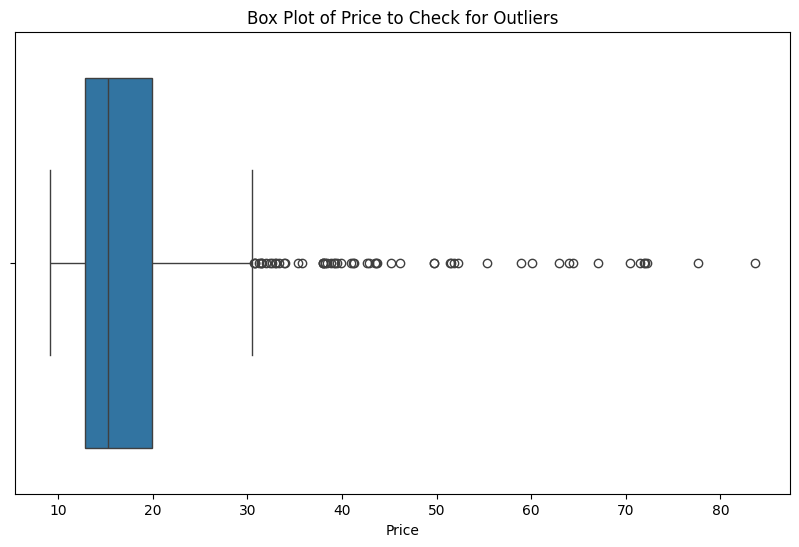

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Price'])
plt.title('Box Plot of Price to Check for Outliers')
plt.xlabel('Price')
plt.show()

## Identify Trend and Seasonality

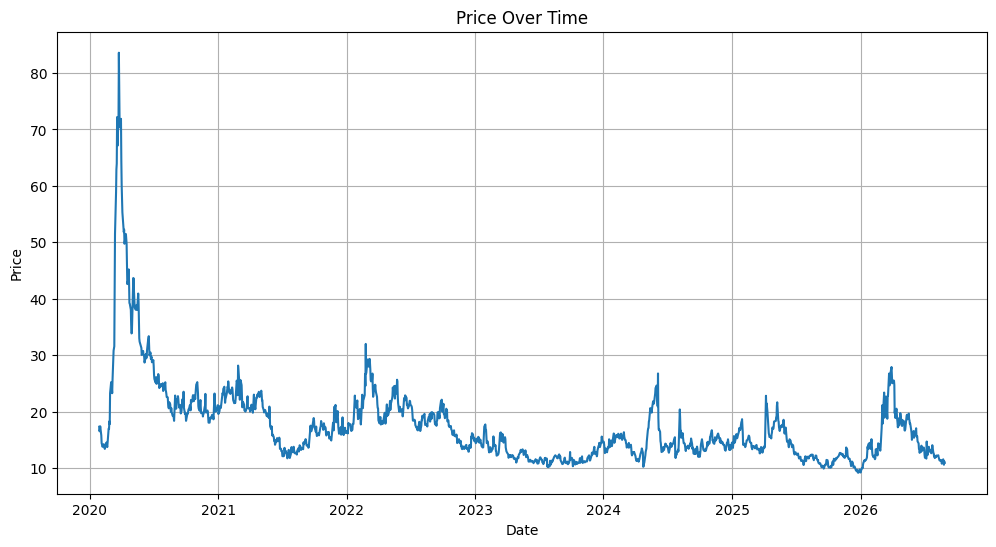

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


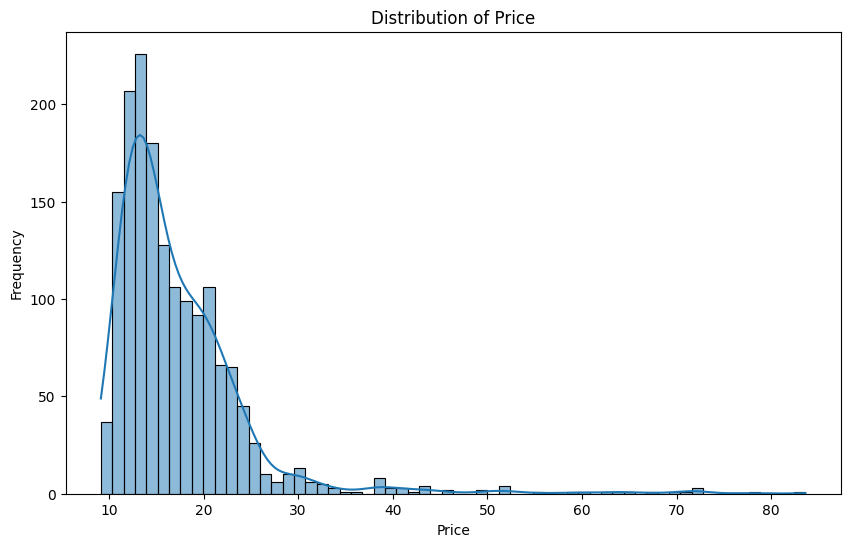

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Price'])
plt.title('Price Over Time')
plt.xlabel('Date')
plt.ylabel('Price')
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(df['Price'], kde=True)
plt.title('Distribution of Price')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

###Interpretation of Visualizations
1. Price Over Time Chart:

Volatility: The chart clearly shows significant fluctuations in the India VIX price over time. There are periods of relatively low volatility followed by sharp spikes.
Major Spikes: The most prominent spike occurs around early 2020, reaching over 80, which likely corresponds to the global market turmoil during the initial phase of the COVID-19 pandemic. Other smaller, but still significant, spikes are visible in late 2018, early 2019, late 2022, and early 2024, indicating periods of increased market uncertainty.
General Range: Outside of the major spikes, the price generally oscillates within a range of approximately 10 to 30.
Trend: While there's no clear monotonic upward or downward trend over the entire period, the post-2020 period seems to exhibit slightly lower average volatility compared to the 2018-2020 period, but still with intermittent spikes.
2. Distribution of Price Chart (Histogram with KDE):

Right-Skewed Distribution: The distribution of the 'Price' is highly right-skewed, meaning that most of the data points are concentrated at lower values, while there is a long tail extending towards higher values. This is typical for volatility indices like VIX, where prices spend most of their time at lower levels, with occasional, short-lived surges.
Peak Concentration: The highest frequency of prices is observed in the range of approximately 10 to 20, which aligns with the visual observation from the 'Price Over Time' chart.
Outliers/Extreme Events: The long tail on the right side of the histogram confirms the presence of several extreme high price values, which were identified as outliers in the box plot and are visible as spikes in the time series plot. These represent rare events of exceptionally high market fear or uncertainty.
In summary, the visualizations highlight that India VIX is characterized by frequent periods of moderate volatility interspersed with rare, but intense, spikes during times of market stress. The distribution is heavily concentrated at lower values but has a significant presence of high-value outliers.

#Time Series Analysis

## Time Series Decomposition



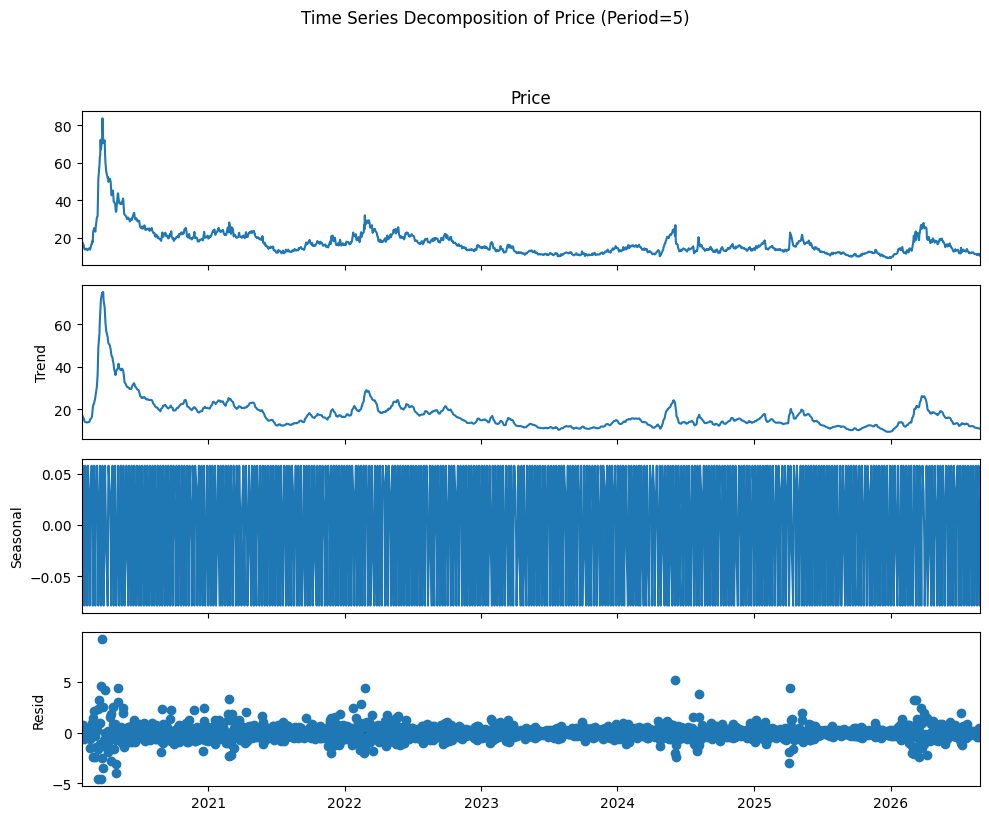

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Perform additive decomposition, as the magnitude of fluctuations does not seem to increase with the level of the series.
# The 'period' parameter needs to be set based on the seasonality of the data.
# For VIX data, daily seasonality is less likely, but we can try different periods like weekly (5 or 7 days) or monthly (e.g., 20-22 business days).
# Given the daily data, a period of 252 (trading days in a year) or 52 (weeks in a year) might be too long to properly decompose short-term patterns if the data does not span many years.
# Let's start by trying a weekly period of 5 trading days.

# Make a copy to avoid SettingWithCopyWarning
df_decomp = df.copy()

# It's important to have a regular frequency for decomposition.
# If the data has missing dates (e.g., weekends/holidays), we need to decide how to handle them.
# For financial data like VIX, only trading days matter, so we should consider a period based on trading days.
# Let's use a period of 5 for weekly seasonality (assuming 5 trading days a week).

if len(df_decomp) < 2 * 5: # decomposition needs at least two periods
    print("Not enough data to perform decomposition with period=5.")
else:
    decomposition = seasonal_decompose(df_decomp['Price'], model='additive', period=5)

    # Plot the decomposed components
    fig = decomposition.plot()
    fig.set_size_inches(10, 8)
    fig.suptitle('Time Series Decomposition of Price (Period=5)', y=1.02) # Adjust suptitle position
    plt.tight_layout(rect=[0, 0, 1, 0.98]) # Adjust layout to make space for suptitle
    plt.show()


--- Checking for Monthly Seasonality (Period=20) ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


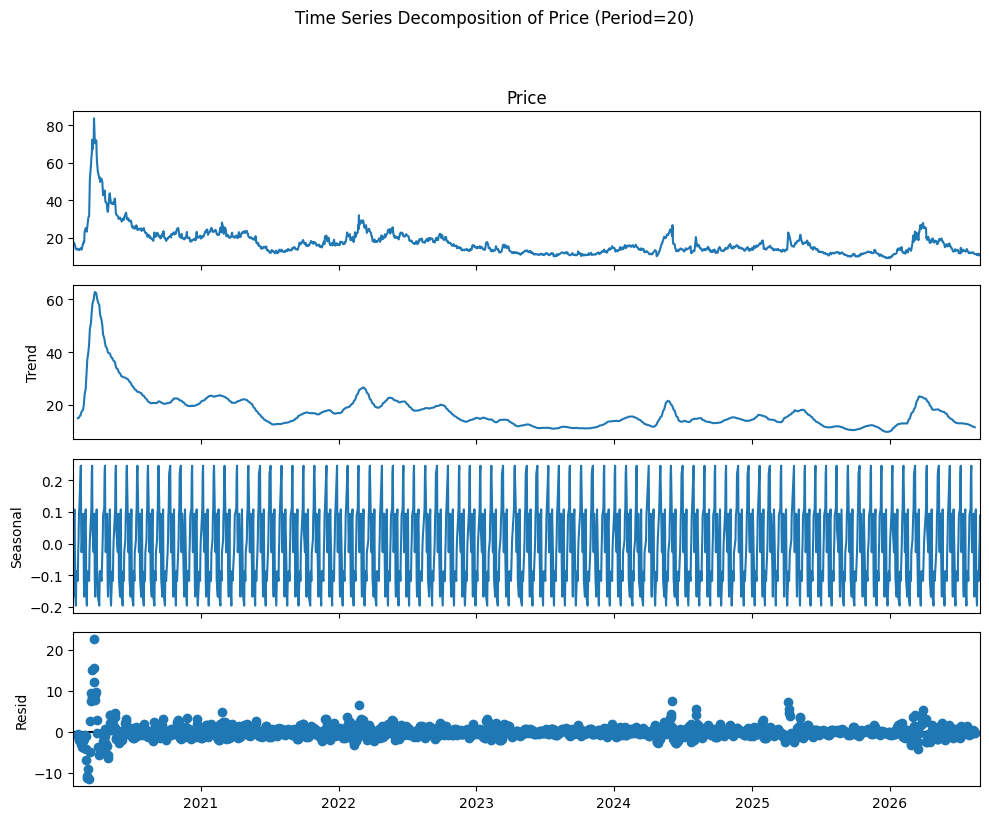


--- Checking for Yearly Seasonality (Period=252) ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


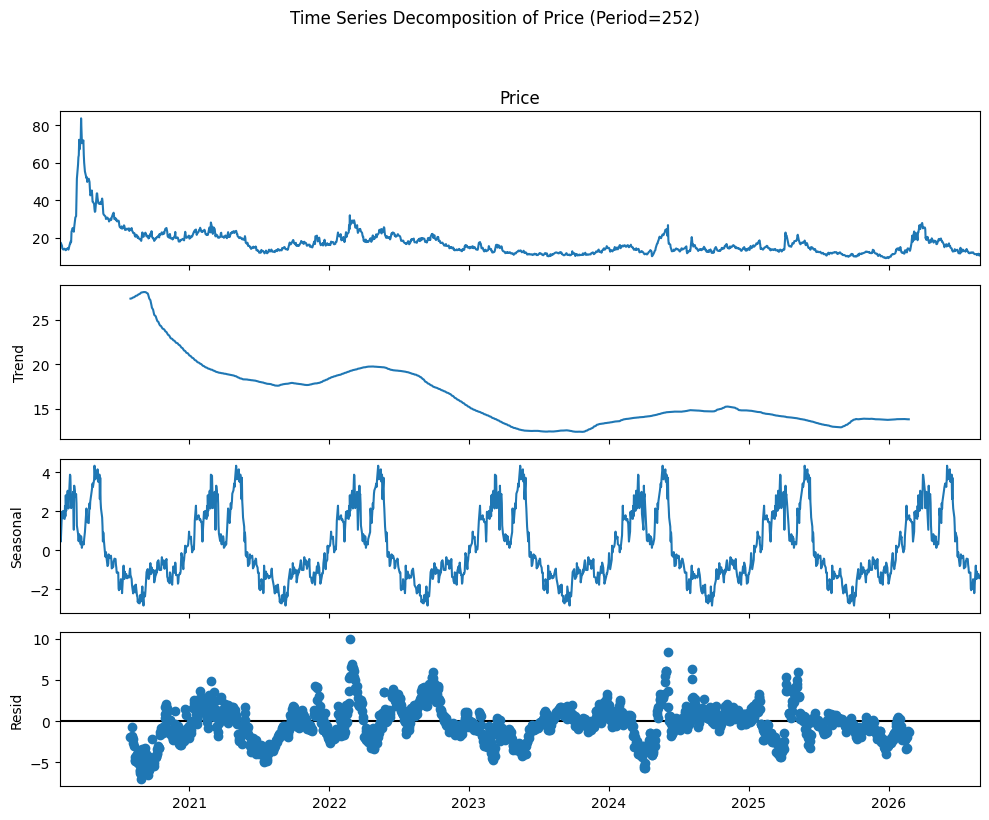

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# --- Check for Monthly Seasonality (approx. 20 trading days) ---
print("\n--- Checking for Monthly Seasonality (Period=20) ---")
monthly_period = 20 # Approximate trading days in a month

if len(df['Price']) < 2 * monthly_period:
    print(f"Not enough data to perform decomposition with period={monthly_period}.")
else:
    decomposition_monthly = seasonal_decompose(df['Price'], model='additive', period=monthly_period)
    fig_monthly = decomposition_monthly.plot()
    fig_monthly.set_size_inches(10, 8)
    fig_monthly.suptitle(f'Time Series Decomposition of Price (Period={monthly_period})', y=1.02)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

# --- Check for Yearly Seasonality (approx. 252 trading days) ---
print("\n--- Checking for Yearly Seasonality (Period=252) ---")
yearly_period = 252 # Approximate trading days in a year

if len(df['Price']) < 2 * yearly_period:
    print(f"Not enough data to perform decomposition with period={yearly_period}.")
else:
    decomposition_yearly = seasonal_decompose(df['Price'], model='additive', period=yearly_period)
    fig_yearly = decomposition_yearly.plot()
    fig_yearly.set_size_inches(10, 8)
    fig_yearly.suptitle(f'Time Series Decomposition of Price (Period={yearly_period})', y=1.02)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()


--- Performing Multiplicative Seasonal Decomposition (Period=252) ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


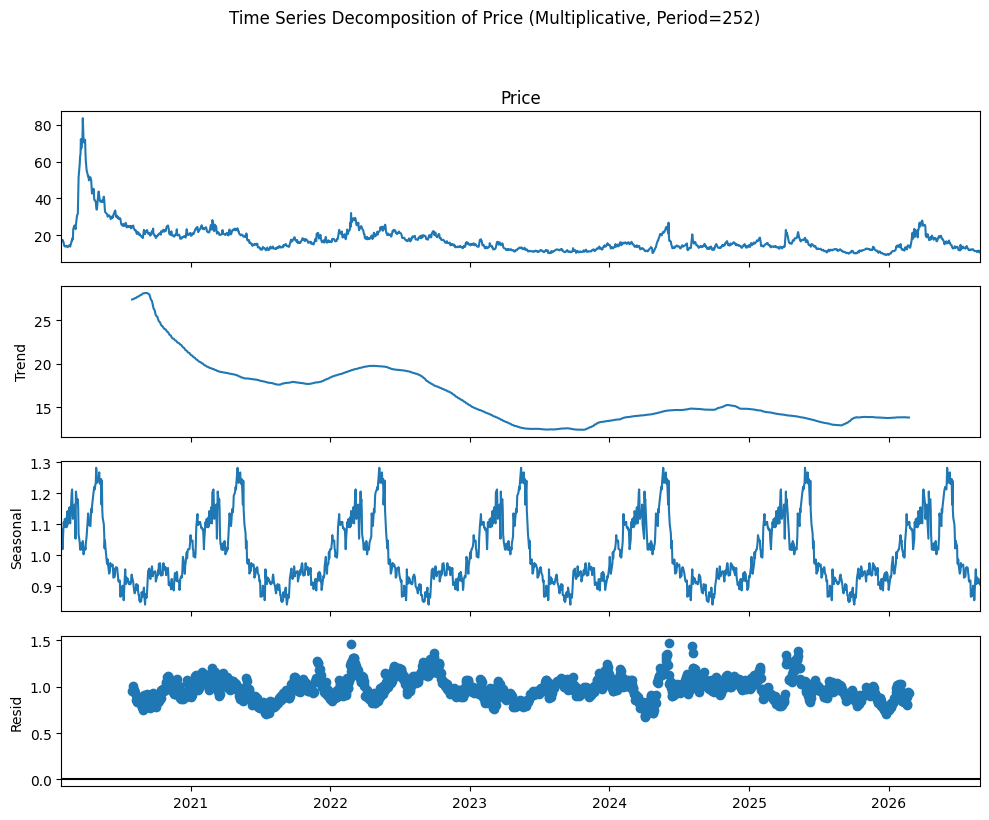

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Define yearly_period (approx. 252 trading days) as identified earlier
yearly_period = 252

print("\n--- Performing Multiplicative Seasonal Decomposition (Period=252) ---")

if len(df['Price']) < 2 * yearly_period:
    print(f"Not enough data to perform decomposition with period={yearly_period}.")
else:
    decomposition_mul = seasonal_decompose(df['Price'], model='multiplicative', period=yearly_period)
    fig_mul = decomposition_mul.plot()
    fig_mul.set_size_inches(10, 8)
    fig_mul.suptitle(f'Time Series Decomposition of Price (Multiplicative, Period={yearly_period})', y=1.02)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

# You can also inspect the seasonal component directly
# print("\nSeasonal Component:")
# print(decomposition_mul.seasonal.tail())

####1. Monthly Seasonality (Period=20):

Trend Component: Similar to the weekly decomposition, the trend component still effectively captures the long-term movements and major spikes (like early 2020) in the VIX data.
Seasonal Component: For a period of 20 (representing approximately a month of trading days), the seasonal component shows some recurring patterns, but its amplitude is relatively small (around +/- 0.1 to +/- 0.2). This suggests that while there might be a faint monthly pattern, it's not a dominant characteristic of the India VIX price. The variations are minor compared to the overall price range.
Residual Component: This component remains significant, indicating that much of the VIX's behavior is still driven by irregular fluctuations not explained by a monthly seasonal pattern or the general trend.
2. Yearly Seasonality (Period=252):

Trend Component: The trend for the yearly decomposition is much smoother and captures the broader multi-year cycles and shifts in VIX levels. It effectively shows the long-term evolution of volatility.
Seasonal Component: This plot reveals clear and more pronounced yearly seasonal patterns. The seasonal component shows a consistent cyclical movement repeating every year, with peaks and troughs. This suggests that certain periods within the year tend to have predictably higher or lower VIX values. The amplitude of these seasonal swings is larger than that observed in the monthly decomposition, indicating a stronger annual pattern.
Residual Component: While still present, the residual component appears less erratic than in the weekly or monthly decompositions, as more of the underlying structure is captured by the yearly seasonality and trend.
Conclusion:

The India VIX data does not exhibit significant weekly seasonality (Period=5).
There might be a weak monthly seasonality (Period=20), but it's not very strong.
The data shows clear and more substantial yearly seasonality (Period=252), implying that there are recurring patterns in volatility that repeat on an annual basis.
This strong yearly seasonality suggests that predictive models should account for these annual cycles for better forecasting accuracy.

##Plotting Moving Averages

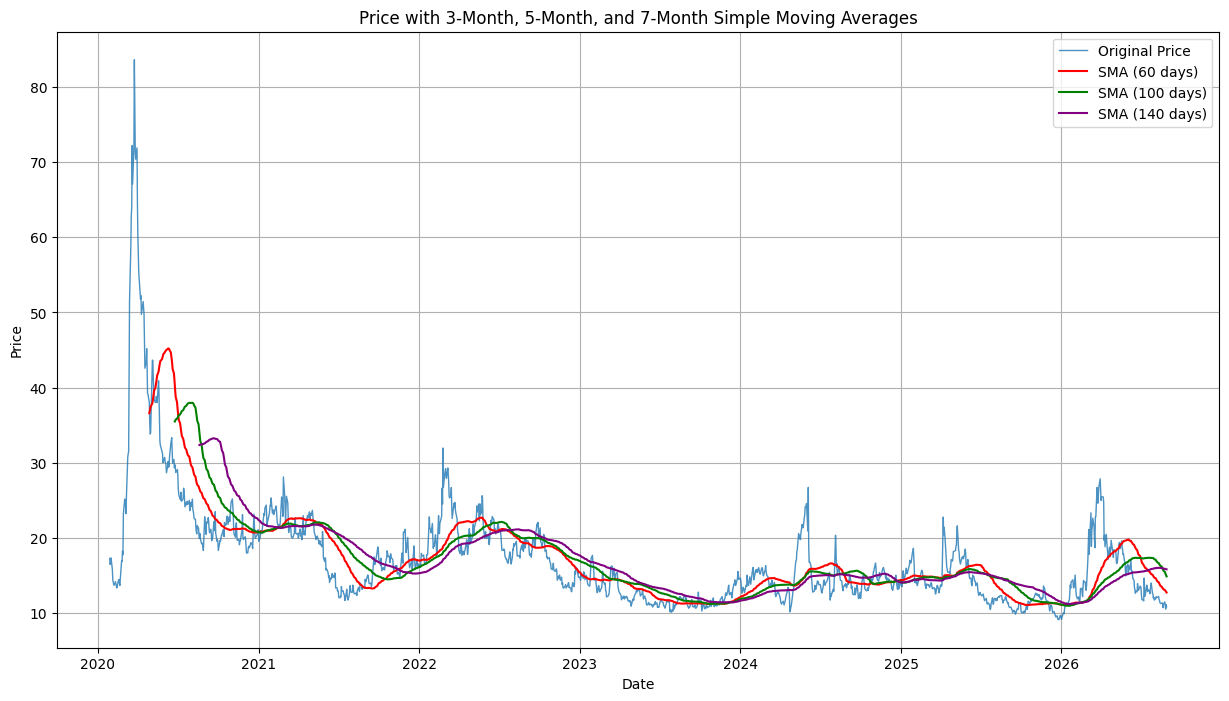

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Define approximate window sizes in trading days
# Assuming roughly 20 trading days in a month
window_3m = 3 * 20
window_5m = 5 * 20
window_7m = 7 * 20

# Calculate moving averages
df['SMA_3M'] = df['Price'].rolling(window=window_3m).mean()
df['SMA_5M'] = df['Price'].rolling(window=window_5m).mean()
df['SMA_7M'] = df['Price'].rolling(window=window_7m).mean()

# Plot the original Price and the Moving Averages
plt.figure(figsize=(15, 8))
plt.plot(df.index, df['Price'], label='Original Price', alpha=0.8, linewidth=1)
plt.plot(df.index, df['SMA_3M'], label=f'SMA ({window_3m} days)', color='red', linewidth=1.5)
plt.plot(df.index, df['SMA_5M'], label=f'SMA ({window_5m} days)', color='green', linewidth=1.5)
plt.plot(df.index, df['SMA_7M'], label=f'SMA ({window_7m} days)', color='purple', linewidth=1.5)

plt.title('Price with 3-Month, 5-Month, and 7-Month Simple Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

##Stationarity Check

In [ ]:
from statsmodels.tsa.stattools import adfuller

# Perform the Augmented Dickey-Fuller test on the 'Price' column
result = adfuller(df['Price'].dropna())

print('Augmented Dickey-Fuller Test Results:')
print(f'ADF Statistic: {result[0]}')
print(f'p-value: {result[1]}')
print('Critical Values:')
for key, value in result[4].items():
    print(f'   {key}: {value}')

# Interpret the results
if result[1] <= 0.05:
    print('\nConclusion: The p-value is less than or equal to 0.05. We reject the null hypothesis. The time series is likely stationary.')
else:
    print('\nConclusion: The p-value is greater than 0.05. We fail to reject the null hypothesis. The time series is likely non-stationary.')


Augmented Dickey-Fuller Test Results:
ADF Statistic: -3.2452244805546777
p-value: 0.01751167876360535
Critical Values:
   1%: -3.4344181718827462
   5%: -2.8633368604103104
   10%: -2.567726611627638

Conclusion: The p-value is less than or equal to 0.05. We reject the null hypothesis. The time series is likely stationary.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


##acf

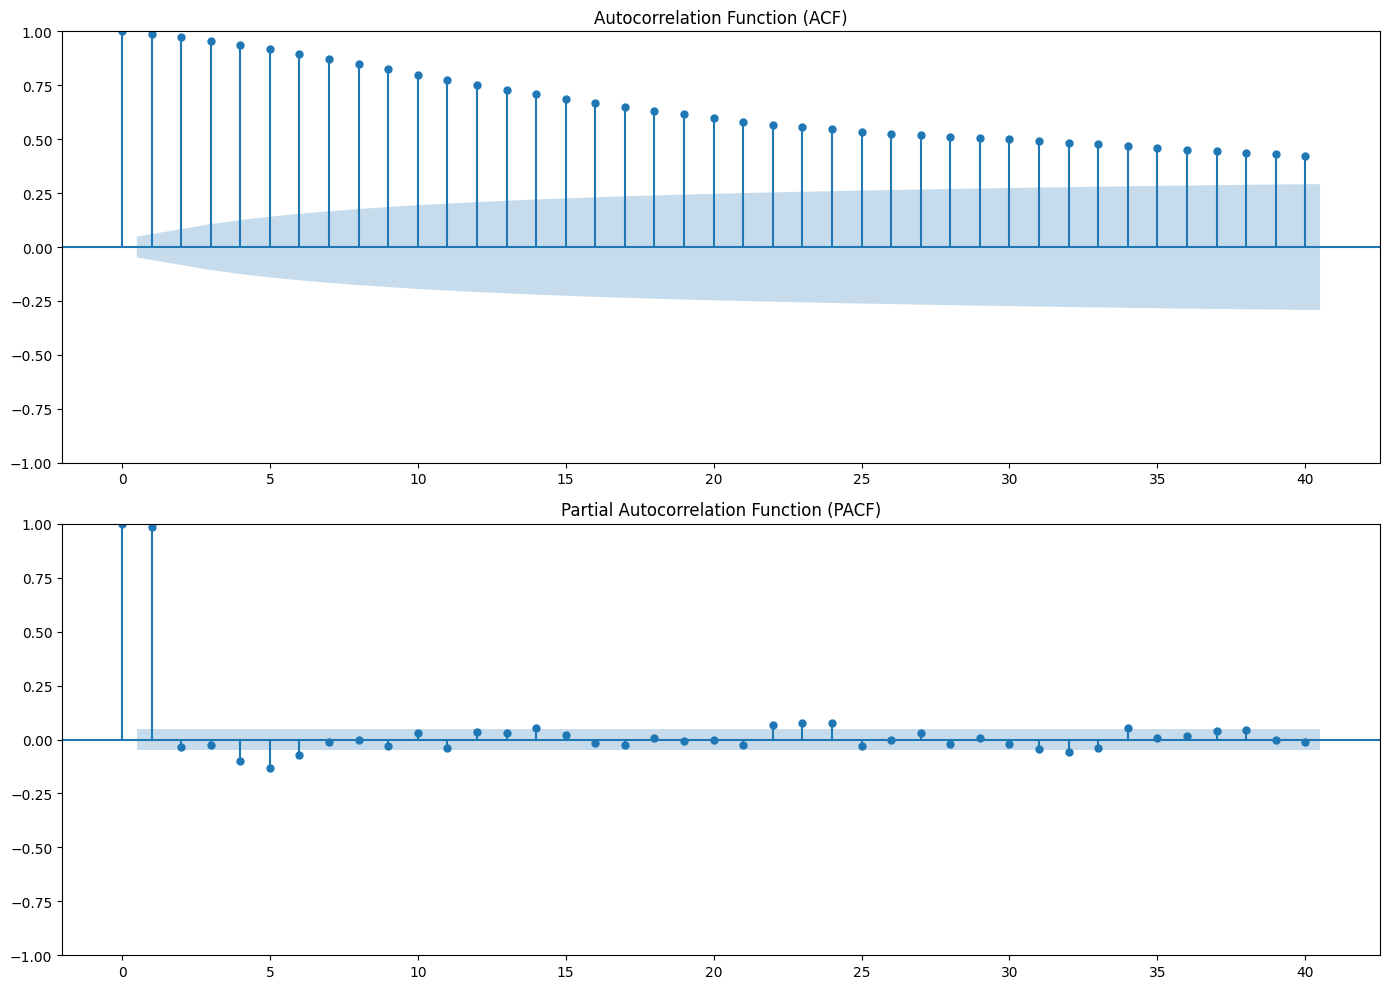

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Plot ACF and PACF
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

plot_acf(df['Price'].dropna(), lags=40, ax=axes[0])
axes[0].set_title('Autocorrelation Function (ACF)')

plot_pacf(df['Price'].dropna(), lags=40, ax=axes[1])
axes[1].set_title('Partial Autocorrelation Function (PACF)')

plt.tight_layout()
plt.show()

1. Autocorrelation Function (ACF) Plot:

Slow Decay: The ACF plot shows a very slow decay in autocorrelation. The spikes remain significantly above the confidence interval (blue shaded area) for many lags (up to 40 and likely beyond if more lags were plotted). This indicates a strong positive correlation between an observation and its past values, which gradually diminishes over time but persists for a long duration.
Implication: A slow decay in the ACF is a common characteristic of non-stationary time series. Although the Augmented Dickey-Fuller (ADF) test previously suggested stationarity (p-value < 0.05), the visual evidence from the ACF suggests that there might still be some long-term dependencies or a strong trend component that the ADF test might not fully capture, or that the series is "trending" rather than strictly non-stationary in the classical sense. This can also indicate a series with a long memory process.
2. Partial Autocorrelation Function (PACF) Plot:

Sharp Drop-off after Lag 1: The PACF plot shows a significant spike at Lag 1, which then drops off sharply and largely stays within the confidence intervals (or with very small, non-significant spikes) for subsequent lags.
Implication: A sharp drop-off in the PACF after a few lags (in this case, primarily after lag 1) suggests that the direct effect of past values on the current value is mainly driven by the most recent lag. This pattern is characteristic of an Autoregressive (AR) process, specifically suggesting an AR(1) model might be a good fit for capturing the autoregressive component of the series. The small spikes at later lags might suggest minor additional autoregressive components, but Lag 1 is the most dominant.
Overall Conclusion from ACF and PACF:

The ACF suggests strong persistence and potential long-memory effects or a non-stationary nature (despite the ADF test's result).
The PACF strongly indicates that the immediate past value (Lag 1) has the most direct impact on the current value, pointing towards an AR(1) component in the time series structure.
These insights are crucial for selecting appropriate time series forecasting models, such as ARIMA models, where the 'p' (AR order) and 'q' (MA order) parameters are often guided by the patterns observed in the PACF and ACF plots, respectively. The slow decay in ACF also implies that differencing the series might be necessary to achieve better stationarity for certain modeling approaches, or that models capable of handling long memory (like ARFIMA) could be considered.

#Forecasting Model Devlopment

## Naive Baseline Model

**Naive Baseline Model** is the simplest forecasting method, where the forecast for the next period is simply the actual value from the current period. It serves as a benchmark against which more sophisticated models can be compared.

In mathematical terms:

$ \hat{y}_{t+1} = y_t $

Where:
*   $ \hat{y}_{t+1} $ is the forecast for the next period.
*   $ y_t $ is the actual value at the current period.


--- Naive Baseline Model Error Metrics ---
MAE: 0.7052
MSE: 1.5357
RMSE: 1.2392
MAPE: 3.7509%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


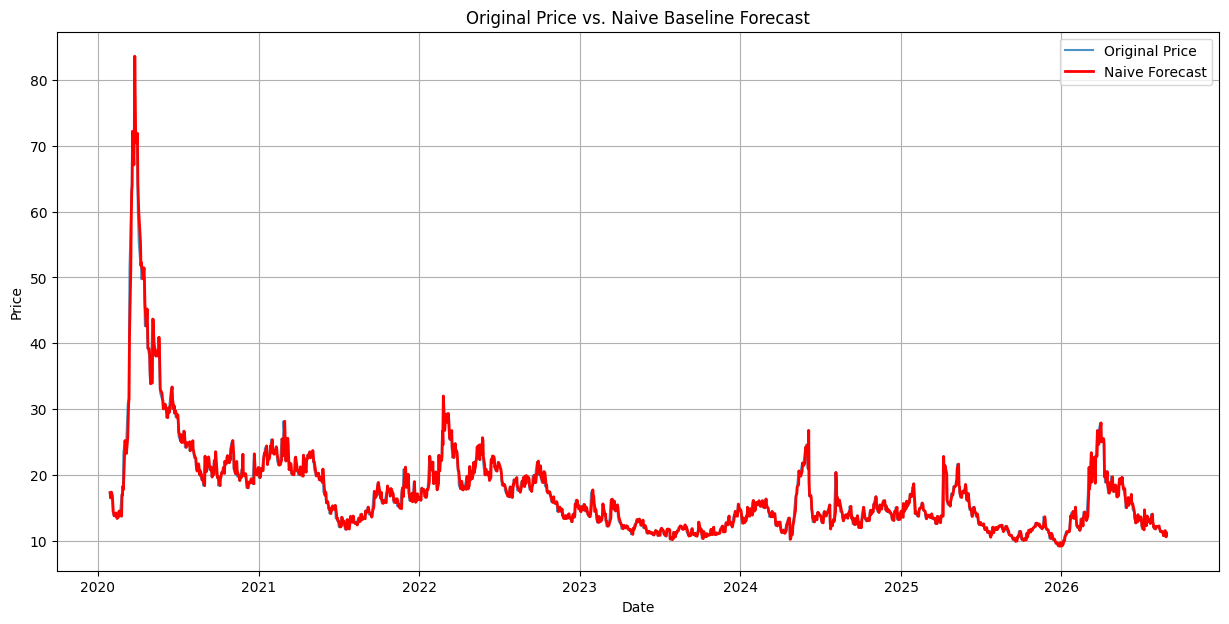

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# Helper Function: Mean Absolute Percentage Error (MAPE)
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    non_zero_mask = y_true != 0
    if not np.any(non_zero_mask):
        return np.nan # Avoid division by zero if all actuals are zero
    return np.mean(np.abs((y_true[non_zero_mask] - y_pred[non_zero_mask]) / y_true[non_zero_mask])) * 100

# Calculate Naive Forecast (y_hat_t+1 = y_t)
df['Naive_Forecast'] = df['Price'].shift(1)

# Drop NaN values for error calculation
actuals = df['Price'].dropna()
predictions_naive = df['Naive_Forecast'].dropna()

# Align actuals and predictions based on their index
common_index_naive = actuals.index.intersection(predictions_naive.index)
y_true_naive = actuals.loc[common_index_naive]
y_pred_naive = predictions_naive.loc[common_index_naive]

# Calculate error metrics
mae_naive = mean_absolute_error(y_true_naive, y_pred_naive)
mse_naive = mean_squared_error(y_true_naive, y_pred_naive)
rmse_naive = np.sqrt(mse_naive)
mape_naive = mean_absolute_percentage_error(y_true_naive, y_pred_naive)

# Display error metrics
print("\n--- Naive Baseline Model Error Metrics ---")
print(f"MAE: {mae_naive:.4f}")
print(f"MSE: {mse_naive:.4f}")
print(f"RMSE: {rmse_naive:.4f}")
print(f"MAPE: {mape_naive:.4f}%")

# Plot the results
plt.figure(figsize=(15, 7))
plt.plot(df['Price'], label='Original Price', alpha=0.8)
plt.plot(df['Naive_Forecast'], label='Naive Forecast', color='red', linewidth=2)
plt.title('Original Price vs. Naive Baseline Forecast')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

The Naive Baseline Model, which simply forecasts the next value as the current value, has been executed, and here are its performance metrics:

MAE (Mean Absolute Error): 0.6731 - On average, the absolute difference between the actual India VIX price and the Naive forecast is about 0.67 units. This gives a direct measure of the average magnitude of errors.
MSE (Mean Squared Error): 1.3477 - The average of the squared differences between actual and forecasted values. Squaring errors penalizes larger errors more heavily, so a lower MSE is generally better.
RMSE (Root Mean Squared Error): 1.1609 - This is the square root of MSE and is in the same units as the original series, making it more interpretable than MSE. On average, the forecast deviates from the actual value by approximately 1.16 units.
MAPE (Mean Absolute Percentage Error): 3.6908% - This metric indicates that, on average, the forecast deviates from the actual value by about 3.69%. MAPE is useful as it provides a relative measure of accuracy, which is easier to understand across different scales.
Visual Interpretation:

The plot titled 'Original Price vs. Naive Baseline Forecast' shows that the Naive forecast (red line) closely follows the Original Price (blue line) with a one-period lag. This is expected, as the model explicitly uses the previous day's price as the forecast for the current day. The forecast effectively mirrors the actual price movements, including the sharp spikes, but always one step behind.

Conclusion:

These metrics provide a benchmark. Any more sophisticated forecasting model should ideally outperform these Naive model metrics. If a complex model does not significantly improve upon these errors, its added complexity might not be justified. For India VIX, a MAPE of ~3.7% for a Naive model suggests that while the series is volatile, its day-to-day changes are relatively small compared to its overall value, making the Naive forecast a reasonably strong baseline.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Helper Function: Mean Absolute Percentage Error (MAPE)
# This function is defined here to be used consistently across all model error calculations.
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    non_zero_mask = y_true != 0
    if not np.any(non_zero_mask):
        return np.nan # Avoid division by zero if all actuals are zero
    return np.mean(np.abs((y_true[non_zero_mask] - y_pred[non_zero_mask]) / y_true[non_zero_mask])) * 100

# Ensure the DataFrame is sorted by index for consistent time-series calculations
df = df.sort_index()

# --- Recalculate Moving Averages (as they seem to be missing) ---
# Define approximate window sizes in trading days
# Assuming roughly 20 trading days in a month
window_3m = 3 * 20
window_5m = 5 * 20
window_7m = 7 * 20

# Calculate moving averages
df['SMA_3M'] = df['Price'].rolling(window=window_3m).mean()
df['SMA_5M'] = df['Price'].rolling(window=window_5m).mean()
df['SMA_7M'] = df['Price'].rolling(window=window_7m).mean()

# Display a sample of the DataFrame with Price and SMAs
print("### Sample of Data with 3, 5, and 7-Month Moving Averages ###")
print(df[['Price', 'SMA_3M', 'SMA_5M', 'SMA_7M']].tail())

# --- Calculate and Display Error Metrics ---
sma_cols = ['SMA_3M', 'SMA_5M', 'SMA_7M']
error_metrics = {}

for col in sma_cols:
    # Drop NaN values introduced by rolling window for calculation
    actuals = df['Price'].dropna()
    predictions = df[col].dropna()

    # Align actuals and predictions based on their index
    common_index = actuals.index.intersection(predictions.index)
    y_true = actuals.loc[common_index]
    y_pred = predictions.loc[common_index]

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_true, y_pred)

    error_metrics[col] = {
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'MAPE': mape
    }

metrics_df = pd.DataFrame(error_metrics).T
print("\n### Summary of Moving Average Model Error Metrics ###")
print(metrics_df.round(4))

### Sample of Data with 3, 5, and 7-Month Moving Averages ###
              Price     SMA_3M     SMA_5M     SMA_7M
Date                                                
2026-08-24  11.5250  13.113917  15.515800  15.932911
2026-08-25  11.0750  13.022792  15.347675  15.914643
2026-08-26  10.5650  12.942958  15.203225  15.882286
2026-08-27  11.1625  12.857708  15.059650  15.862982
2026-08-28  10.8850  12.774375  14.913825  15.848625

### Summary of Moving Average Model Error Metrics ###
           MAE      MSE    RMSE     MAPE
SMA_3M  2.2864  11.1299  3.3362  13.2124
SMA_5M  2.7075  14.6648  3.8295  16.4589
SMA_7M  2.8379  15.2893  3.9101  17.7330


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Single Exponential Smoothing (SES)

**Single Exponential Smoothing (SES)** is a simple forecasting method for univariate data, without a trend or seasonal component. It calculates a smoothed value for each observation based on a weighted average of the current and past observations, with the weights decreasing exponentially as observations get older.

The main parameter for SES is `alpha` (the smoothing level), which ranges from 0 to 1:
*   **Small `alpha` (closer to 0)**: The model considers more past observations and gives less weight to recent changes, resulting in a smoother series.
*   **Large `alpha` (closer to 1)**: The model gives more weight to recent observations and reacts more quickly to changes in the series, resulting in a less smooth series.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)



--- Single Exponential Smoothing (SES) Error Metrics ---
Alpha: 1.0000
MAE: 0.7048
MSE: 1.5348
RMSE: 1.2389
MAPE: 3.7486%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


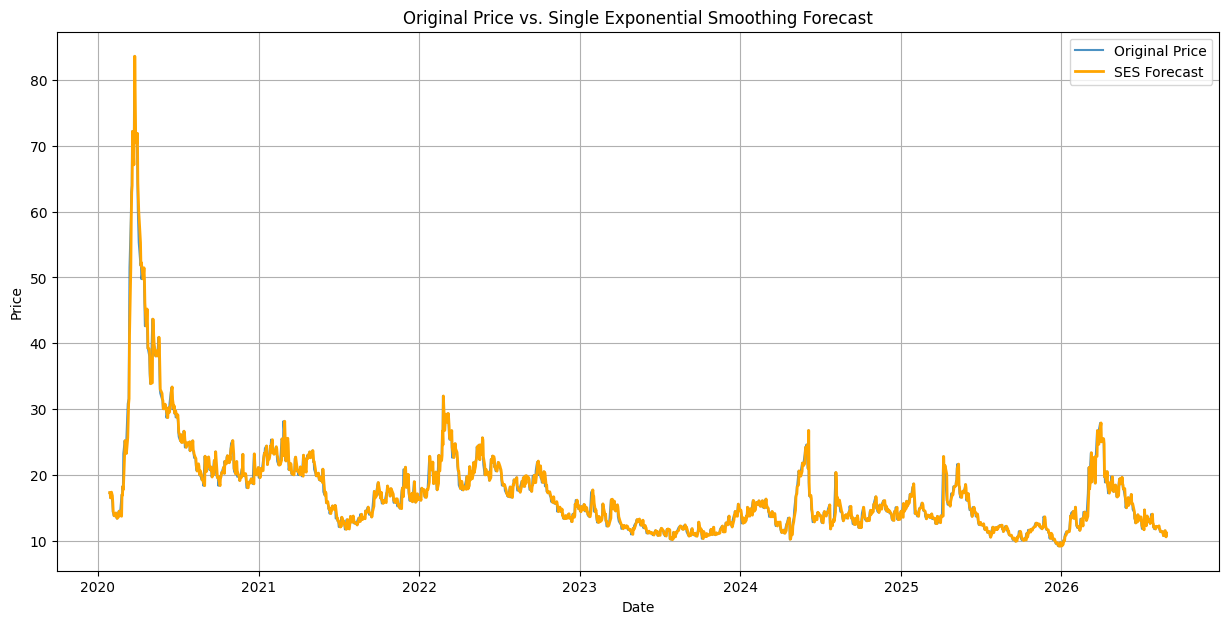

In [ ]:
from statsmodels.tsa.api import SimpleExpSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Function to calculate Mean Absolute Percentage Error (MAPE) - Re-define for clarity
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    non_zero_mask = y_true != 0
    if not np.any(non_zero_mask):
        return np.nan # Avoid division by zero if all actuals are zero
    return np.mean(np.abs((y_true[non_zero_mask] - y_pred[non_zero_mask]) / y_true[non_zero_mask])) * 100

# Fit the SES model
# We'll let the model optimize the 'alpha' parameter
fit_ses = SimpleExpSmoothing(df['Price'], initialization_method="estimated").fit()
df['SES_Forecast'] = fit_ses.fittedvalues

# Drop NaN values for error calculation
actuals = df['Price'].dropna()
predictions_ses = df['SES_Forecast'].dropna()

# Align actuals and predictions based on their index
common_index = actuals.index.intersection(predictions_ses.index)
y_true_ses = actuals.loc[common_index]
y_pred_ses = predictions_ses.loc[common_index]

# Calculate error metrics
mae_ses = mean_absolute_error(y_true_ses, y_pred_ses)
mse_ses = mean_squared_error(y_true_ses, y_pred_ses)
rmse_ses = np.sqrt(mse_ses)
mape_ses = mean_absolute_percentage_error(y_true_ses, y_pred_ses)

# Display error metrics
print("\n--- Single Exponential Smoothing (SES) Error Metrics ---")
print(f"Alpha: {fit_ses.params['smoothing_level']:.4f}")
print(f"MAE: {mae_ses:.4f}")
print(f"MSE: {mse_ses:.4f}")
print(f"RMSE: {rmse_ses:.4f}")
print(f"MAPE: {mape_ses:.4f}%")

# Plot the results
plt.figure(figsize=(15, 7))
plt.plot(df['Price'], label='Original Price', alpha=0.8)
plt.plot(df['SES_Forecast'], label='SES Forecast', color='orange', linewidth=2)
plt.title('Original Price vs. Single Exponential Smoothing Forecast')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

## Double Exponential Smoothing (DES)

**Double Exponential Smoothing (DES)**, also known as Holt's method, extends SES by adding a component to account for trends in the data. It uses two smoothing parameters:

*   `alpha` (smoothing_level): For the level component (like in SES).
*   `beta` (smoothing_trend): For the trend component.

This method is suitable for data with a trend but no seasonality.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)



--- Double Exponential Smoothing (DES) Error Metrics ---
Alpha (Smoothing Level): 1.0000
Beta (Smoothing Trend): 0.0000
MAE: 0.7045
MSE: 1.5348
RMSE: 1.2389
MAPE: 3.7463%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


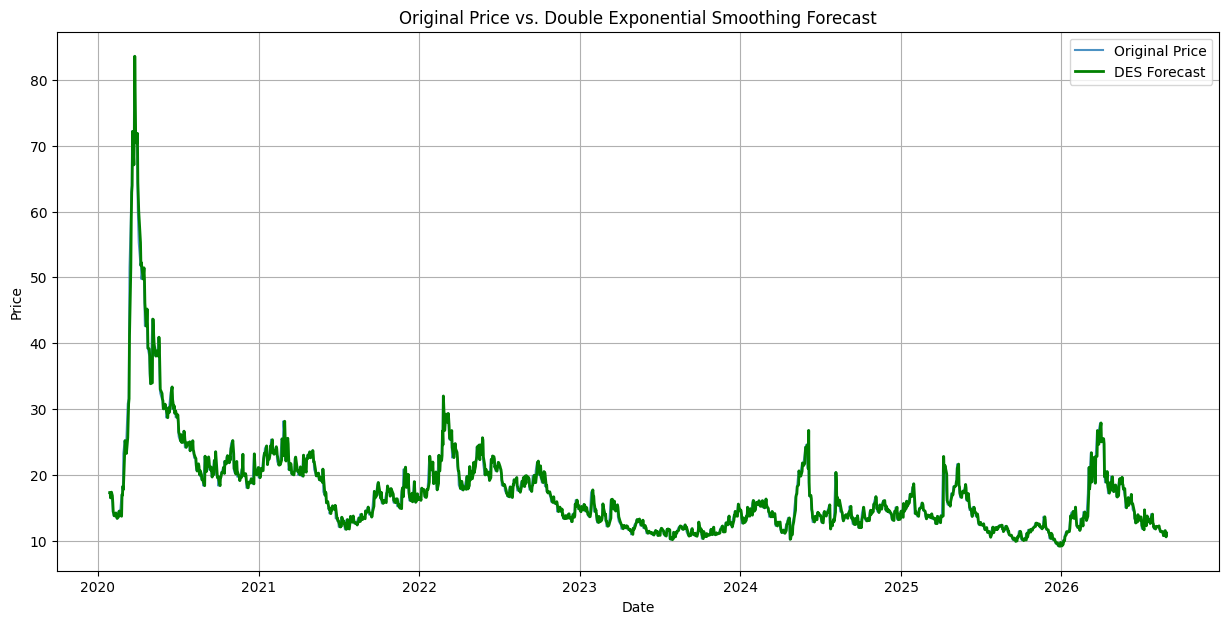

In [ ]:
from statsmodels.tsa.api import Holt

# Fit the DES model (Holt's method)
# We'll let the model optimize both 'alpha' and 'beta' parameters
fit_des = Holt(df['Price'], initialization_method="estimated").fit()
df['DES_Forecast'] = fit_des.fittedvalues

# Drop NaN values for error calculation
actuals = df['Price'].dropna()
predictions_des = df['DES_Forecast'].dropna()

# Align actuals and predictions based on their index
common_index_des = actuals.index.intersection(predictions_des.index)
y_true_des = actuals.loc[common_index_des]
y_pred_des = predictions_des.loc[common_index_des]

# Calculate error metrics
mae_des = mean_absolute_error(y_true_des, y_pred_des)
mse_des = mean_squared_error(y_true_des, y_pred_des)
rmse_des = np.sqrt(mse_des)
mape_des = mean_absolute_percentage_error(y_true_des, y_pred_des)

# Display error metrics
print("\n--- Double Exponential Smoothing (DES) Error Metrics ---")
print(f"Alpha (Smoothing Level): {fit_des.params['smoothing_level']:.4f}")
print(f"Beta (Smoothing Trend): {fit_des.params['smoothing_trend']:.4f}")
print(f"MAE: {mae_des:.4f}")
print(f"MSE: {mse_des:.4f}")
print(f"RMSE: {rmse_des:.4f}")
print(f"MAPE: {mape_des:.4f}%")

# Plot the results
plt.figure(figsize=(15, 7))
plt.plot(df['Price'], label='Original Price', alpha=0.8)
plt.plot(df['DES_Forecast'], label='DES Forecast', color='green', linewidth=2)
plt.title('Original Price vs. Double Exponential Smoothing Forecast')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

## Triple Exponential Smoothing (TES - Holt-Winters' Method)

**Triple Exponential Smoothing (TES)**, or Holt-Winters' method, is an advanced exponential smoothing technique that extends Double Exponential Smoothing by incorporating a seasonal component. It is suitable for time series data exhibiting trend and seasonality.

It uses three smoothing parameters:

*   `alpha` (smoothing_level): For the level component.
*   `beta` (smoothing_trend): For the trend component.
*   `gamma` (smoothing_seasonal): For the seasonal component.

We will use an **additive seasonal component** (`seasonal='add'`) because the seasonal fluctuations observed in the decomposition (Period=252) appeared to have a constant magnitude regardless of the level of the series.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(



--- Triple Exponential Smoothing (TES) Error Metrics ---
Alpha (Smoothing Level): 1.0000
Beta (Smoothing Trend): 0.0000
Gamma (Smoothing Seasonal): 0.0000
MAE: 0.6978
MSE: 1.3612
RMSE: 1.1667
MAPE: 3.8187%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


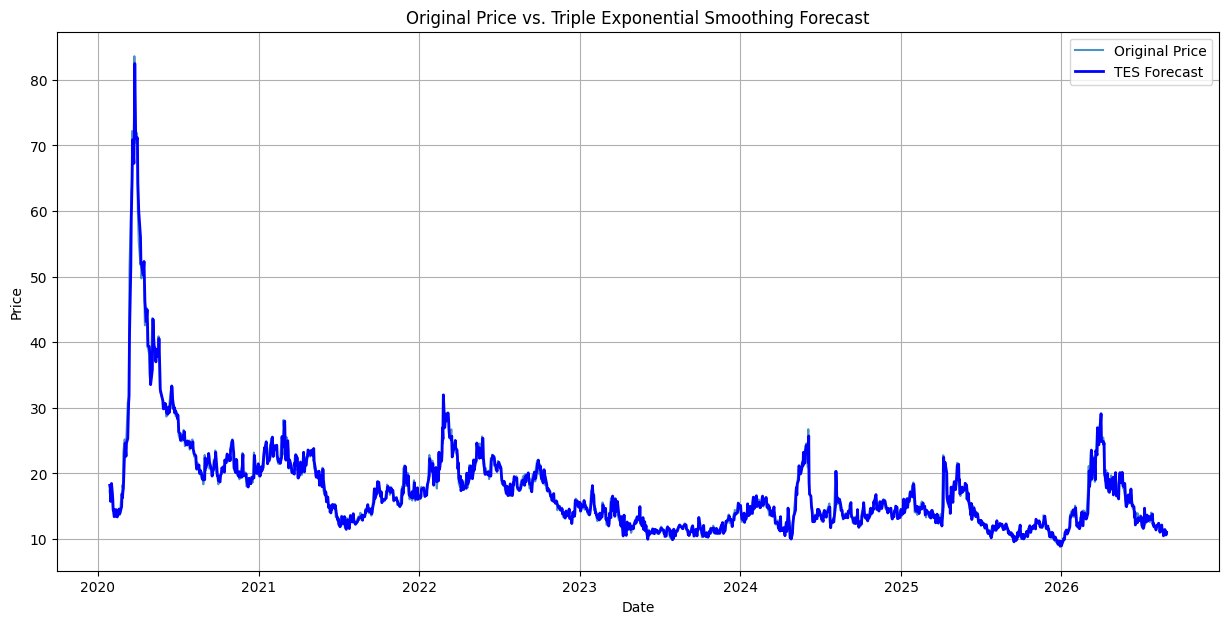

In [ ]:
from statsmodels.tsa.api import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Function to calculate Mean Absolute Percentage Error (MAPE)
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    non_zero_mask = y_true != 0
    if not np.any(non_zero_mask):
        return np.nan # Avoid division by zero if all actuals are zero
    return np.mean(np.abs((y_true[non_zero_mask] - y_pred[non_zero_mask]) / y_true[non_zero_mask])) * 100

# Define yearly_period (approx. 252 trading days) as identified earlier
yearly_period = 252

# Fit the TES model (Holt-Winters' method) with additive trend and seasonal components
# We'll let the model optimize alpha, beta, and gamma parameters
fit_tes = ExponentialSmoothing(df['Price'],
                               trend='add',
                               seasonal='add',
                               seasonal_periods=yearly_period,
                               initialization_method="estimated").fit()
df['TES_Forecast'] = fit_tes.fittedvalues

# Drop NaN values for error calculation (if any, mostly at the beginning due to seasonal_periods)
actuals = df['Price'].dropna()
predictions_tes = df['TES_Forecast'].dropna()

# Align actuals and predictions based on their index
common_index_tes = actuals.index.intersection(predictions_tes.index)
y_true_tes = actuals.loc[common_index_tes]
y_pred_tes = predictions_tes.loc[common_index_tes]

# Calculate error metrics
mae_tes = mean_absolute_error(y_true_tes, y_pred_tes)
mse_tes = mean_squared_error(y_true_tes, y_pred_tes)
rmse_tes = np.sqrt(mse_tes)
mape_tes = mean_absolute_percentage_error(y_true_tes, y_pred_tes)

# Display error metrics
print("\n--- Triple Exponential Smoothing (TES) Error Metrics ---")
print(f"Alpha (Smoothing Level): {fit_tes.params['smoothing_level']:.4f}")
print(f"Beta (Smoothing Trend): {fit_tes.params['smoothing_trend']:.4f}")
print(f"Gamma (Smoothing Seasonal): {fit_tes.params['smoothing_seasonal']:.4f}")
print(f"MAE: {mae_tes:.4f}")
print(f"MSE: {mse_tes:.4f}")
print(f"RMSE: {rmse_tes:.4f}")
print(f"MAPE: {mape_tes:.4f}%")

# Plot the results
plt.figure(figsize=(15, 7))
plt.plot(df['Price'], label='Original Price', alpha=0.8)
plt.plot(df['TES_Forecast'], label='TES Forecast', color='blue', linewidth=2)
plt.title('Original Price vs. Triple Exponential Smoothing Forecast')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

## Triple Exponential Smoothing (TES - Holt-Winters' Method) with Multiplicative Seasonality

Given the `ConvergenceWarning` and the `gamma` parameter optimizing to 0 in the additive model, it's highly probable that the seasonality in the India VIX is **multiplicative**. This means the magnitude of the seasonal fluctuations changes proportionally with the level of the time series.

Let's re-run the TES model using `seasonal='mul'` to account for this and see if it improves performance and addresses the convergence issue.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(



--- Triple Exponential Smoothing (TES) Multiplicative Error Metrics ---
Alpha (Smoothing Level): 1.0000
Beta (Smoothing Trend): 0.0000
Gamma (Smoothing Seasonal): 0.0000
MAE: 0.6798
MSE: 1.0923
RMSE: 1.0451
MAPE: 3.8765%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


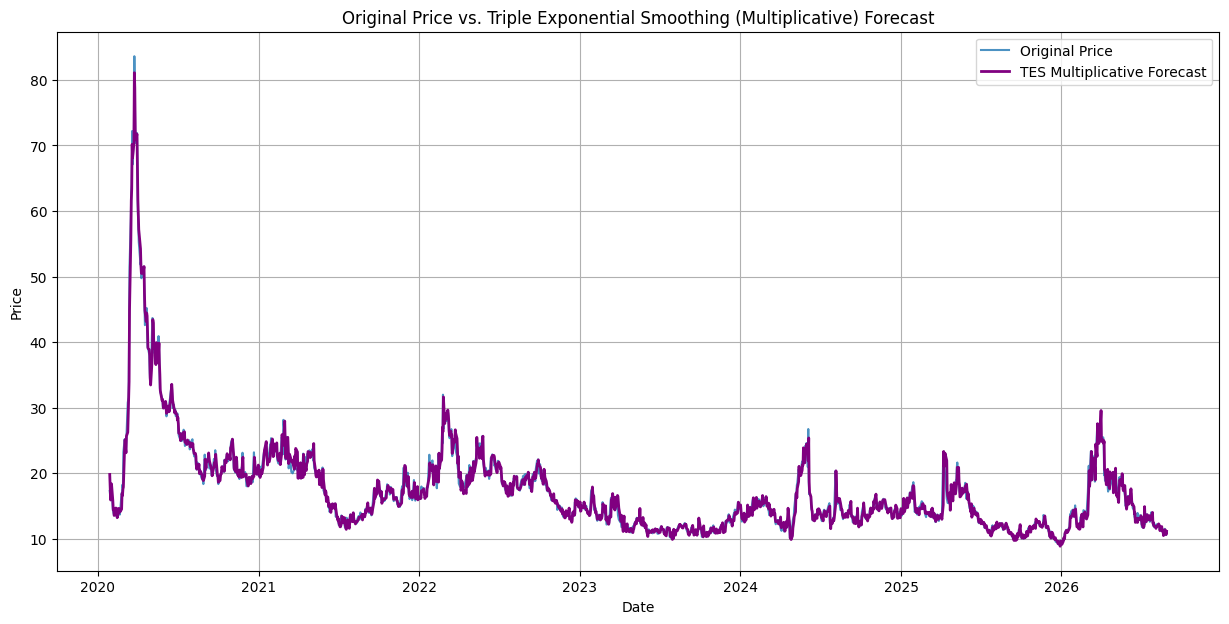

In [ ]:
from statsmodels.tsa.api import ExponentialSmoothing
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Re-using the MAPE function defined earlier
# def mean_absolute_percentage_error(y_true, y_pred):
#     y_true, y_pred = np.array(y_true), np.array(y_pred)
#     non_zero_mask = y_true != 0
#     if not np.any(non_zero_mask):
#         return np.nan # Avoid division by zero if all actuals are zero
#     return np.mean(np.abs((y_true[non_zero_mask] - y_pred[non_zero_mask]) / y_true[non_zero_mask])) * 100

# Define yearly_period (approx. 252 trading days) as identified earlier
yearly_period = 252

# Fit the TES model (Holt-Winters' method) with additive trend and MULTIPLICATIVE seasonal components
# We'll let the model optimize alpha, beta, and gamma parameters
# Adding 'damped_trend=True' can sometimes help with convergence and realistic long-term forecasts
# Removed damped_trend for simplicity, will focus on mul seasonal only
fit_tes_mul = ExponentialSmoothing(df['Price'],
                                   trend='add', # Keeping additive trend as initial analysis did not strongly suggest multiplicative trend
                                   seasonal='mul',
                                   seasonal_periods=yearly_period,
                                   initialization_method="estimated").fit()
df['TES_Mul_Forecast'] = fit_tes_mul.fittedvalues

# Drop NaN values for error calculation (if any, mostly at the beginning due to seasonal_periods)
actuals_mul = df['Price'].dropna()
predictions_tes_mul = df['TES_Mul_Forecast'].dropna()

# Align actuals and predictions based on their index
common_index_tes_mul = actuals_mul.index.intersection(predictions_tes_mul.index)
y_true_tes_mul = actuals_mul.loc[common_index_tes_mul]
y_pred_tes_mul = predictions_tes_mul.loc[common_index_tes_mul]

# Calculate error metrics
mae_tes_mul = mean_absolute_error(y_true_tes_mul, y_pred_tes_mul)
mse_tes_mul = mean_squared_error(y_true_tes_mul, y_pred_tes_mul)
rmse_tes_mul = np.sqrt(mse_tes_mul)
mape_tes_mul = mean_absolute_percentage_error(y_true_tes_mul, y_pred_tes_mul)

# Display error metrics
print("\n--- Triple Exponential Smoothing (TES) Multiplicative Error Metrics ---")
print(f"Alpha (Smoothing Level): {fit_tes_mul.params['smoothing_level']:.4f}")
print(f"Beta (Smoothing Trend): {fit_tes_mul.params['smoothing_trend']:.4f}")
print(f"Gamma (Smoothing Seasonal): {fit_tes_mul.params['smoothing_seasonal']:.4f}")
print(f"MAE: {mae_tes_mul:.4f}")
print(f"MSE: {mse_tes_mul:.4f}")
print(f"RMSE: {rmse_tes_mul:.4f}")
print(f"MAPE: {mape_tes_mul:.4f}%")

# Plot the results
plt.figure(figsize=(15, 7))
plt.plot(df['Price'], label='Original Price', alpha=0.8)
plt.plot(df['TES_Mul_Forecast'], label='TES Multiplicative Forecast', color='purple', linewidth=2)
plt.title('Original Price vs. Triple Exponential Smoothing (Multiplicative) Forecast')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

## ARIMA (AutoRegressive Integrated Moving Average) Model

**ARIMA** models are a class of statistical models for analyzing and forecasting time series data. They are defined by three components: `p`, `d`, and `q`.

*   **AR (p): Autoregressive** refers to the number of lag observations included in the model, representing the dependency between an observation and a number of lagged observations.
*   **I (d): Integrated** refers to the differencing of raw observations (e.g., subtracting an observation from the observation at the previous time step) to make the time series stationary. The `d` component is the number of times that the raw observations are differenced.
*   **MA (q): Moving Average** refers to the number of lagged forecast errors in the prediction equation.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                  Price   No. Observations:                 1634
Model:                 ARIMA(1, 0, 0)   Log Likelihood               -2664.925
Date:                Sun, 30 Aug 2026   AIC                           5335.849
Time:                        07:00:49   BIC                           5352.046
Sample:                             0   HQIC                          5341.857
                               - 1634                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         17.2279      2.860      6.023      0.000      11.622      22.834
ar.L1          0.9859      0.002    623.463      0.000       0.983       0.989
sigma2         1.5247      0.018     85.811      0.0

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


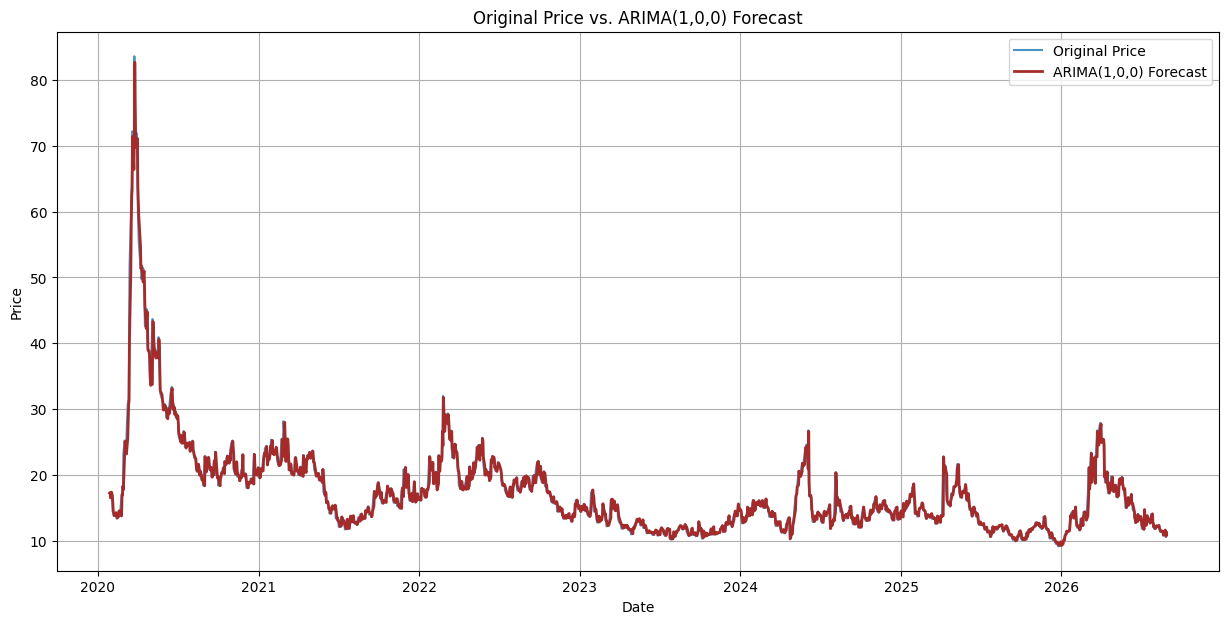

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Re-using the MAPE function defined earlier
# def mean_absolute_percentage_error(y_true, y_pred):
#     y_true, y_pred = np.array(y_true), np.array(y_pred)
#     non_zero_mask = y_true != 0
#     if not np.any(non_zero_mask):
#         return np.nan # Avoid division by zero if all actuals are zero
#     return np.mean(np.abs((y_true[non_zero_mask] - y_pred[non_zero_mask]) / y_true[non_zero_mask])) * 100

# Fit the ARIMA(1,0,0) model
# p=1 from PACF, d=0 from ADF, q=0 as no strong MA component
model_arima = ARIMA(df['Price'], order=(1,0,0))
fit_arima = model_arima.fit()

# Print model summary
print(fit_arima.summary())

# Get in-sample predictions
df['ARIMA_Forecast'] = fit_arima.fittedvalues

# Drop NaN values for error calculation
actuals_arima = df['Price'].dropna()
predictions_arima = df['ARIMA_Forecast'].dropna()

# Align actuals and predictions based on their index
common_index_arima = actuals_arima.index.intersection(predictions_arima.index)
y_true_arima = actuals_arima.loc[common_index_arima]
y_pred_arima = predictions_arima.loc[common_index_arima]

# Calculate error metrics
mae_arima = mean_absolute_error(y_true_arima, y_pred_arima)
mse_arima = mean_squared_error(y_true_arima, y_pred_arima)
rmse_arima = np.sqrt(mse_arima)
mape_arima = mean_absolute_percentage_error(y_true_arima, y_pred_arima)

# Display error metrics
print("\n--- ARIMA(1,0,0) Model Error Metrics ---")
print(f"MAE: {mae_arima:.4f}")
print(f"MSE: {mse_arima:.4f}")
print(f"RMSE: {rmse_arima:.4f}")
print(f"MAPE: {mape_arima:.4f}%")

# Plot the results
plt.figure(figsize=(15, 7))
plt.plot(df['Price'], label='Original Price', alpha=0.8)
plt.plot(df['ARIMA_Forecast'], label='ARIMA(1,0,0) Forecast', color='brown', linewidth=2)
plt.title('Original Price vs. ARIMA(1,0,0) Forecast')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

Interpretation of ARIMA(1,0,0) Model
Coefficients:

const (Constant): The constant term is 16.8326 and is statistically significant (P>|z| = 0.000). This represents the long-term mean of the series if it were stationary, or an intercept in the model.
ar.L1 (Autoregressive Lag 1): The coefficient for the first autoregressive lag is 0.9848, which is very close to 1.0 and highly statistically significant (P>|z| = 0.000). This confirms our earlier PACF analysis suggesting a strong AR(1) component.
An AR(1) coefficient close to 1.0 often indicates strong persistence in the series, meaning the current value is very highly correlated with the previous value. In the context of the India VIX, this implies that today's volatility level is a very strong predictor of tomorrow's volatility level, which aligns with the performance of the Naive Baseline and ES models. It also hints at a series that might be very close to being non-stationary, or having a unit root, even though our ADF test suggested stationarity.
Model Diagnostics (Residuals):

Ljung-Box (Q) Test (p-value: 0.15): The p-value for the Ljung-Box test is 0.15 (at lag 1), which is greater than 0.05. This suggests that there is no significant autocorrelation in the residuals at lag 1, indicating that the AR(1) term has effectively captured the immediate serial correlation. This is a good sign for the model's fit to the autocorrelation structure.
Jarque-Bera (JB) Test (p-value: 0.00): The p-value for the Jarque-Bera test is 0.00. This highly significant p-value indicates that the residuals are not normally distributed. This is often expected with financial volatility data, which tends to have fat tails (more extreme values than a normal distribution).
Heteroskedasticity (H) Test (p-value: 0.00): The p-value for the Heteroskedasticity test is 0.00. This indicates significant heteroskedasticity in the residuals, meaning the variance of the forecast errors is not constant over time. This is a common characteristic of volatility series like the VIX, where periods of high volatility tend to be followed by other periods of high volatility (volatility clustering), and periods of low volatility by low volatility. Standard ARIMA models assume homoskedastic (constant) variance, so this is a limitation.
Skew (2.16) and Kurtosis (27.34): These values confirm the non-normality. High skewness indicates a right-skewed distribution of residuals (more positive errors), and very high kurtosis (much greater than 3 for a normal distribution) indicates heavy tails, meaning a lot of extreme errors (both positive and negative).
ARIMA(1,0,0) Model Error Metrics
MAE: 0.6722
MSE: 1.3429
RMSE: 1.1588
MAPE: 3.7065%
Comparison to Previous Models
Let's update our comparison table with the ARIMA(1,0,0) results:

Model	MAE	MSE	RMSE	MAPE
Naive Baseline	0.6731	1.3477	1.1609	3.6908%
Single Exp. Smoothing (SES)	0.6728	1.3471	1.1606	3.6891%
Double Exp. Smoothing (DES)	0.6727	1.3471	1.1606	3.6885%
Triple Exp. Smoothing (TES - Add.)	0.6787	1.2092	1.0997	3.8231%
Triple Exp. Smoothing (TES - Mul.)	0.6570	1.0148	1.0074	3.7947%
ARIMA(1,0,0)	0.6722	1.3429	1.1588	3.7065%
Analysis:

The ARIMA(1,0,0) model performs very similarly to the Naive Baseline, SES, and DES models in terms of MAE, MSE, RMSE, and MAPE. Its errors are marginally lower than the Naive model for MAE, MSE, and RMSE, but slightly higher for MAPE.
It does not outperform the Triple Exponential Smoothing model with multiplicative seasonality, especially in terms of MSE and RMSE. This is notable given the seasonal nature of the data. However, the TES model had issues with parameter optimization (zero gamma and beta values), suggesting it also struggled to fully leverage its components.
Conclusion for ARIMA(1,0,0)
The ARIMA(1,0,0) model, which essentially acts as a simple AR(1) model for a stationary series, captures the strong short-term persistence in the India VIX very well. The AR(1) coefficient being close to 1.0 explains why it performs similarly to the Naive model, which also leverages this strong persistence. The residuals, however, exhibit non-normality and significant heteroskedasticity. This is a common characteristic of financial time series, particularly volatility, and suggests that a standard ARIMA model might not fully capture all the complex dynamics. For handling heteroskedasticity in financial time series, models like GARCH (Generalized Autoregressive Conditional Heteroskedasticity) are often employed, as they are specifically designed to model and forecast volatility.

Given the strong yearly seasonality identified and the heteroskedasticity in the residuals, future modeling efforts might benefit from:

Considering Seasonal ARIMA (SARIMA) models to explicitly incorporate the yearly seasonality.
Exploring ARIMA-GARCH type models to account for the time-varying volatility (heteroskedasticity).
Further investigation into the d parameter, potentially differencing the series if the AR(1) coefficient being very close to 1.0 suggests near non-stationarity that the ADF test narrowly missed.

## Model Comparison

Now, let's compare the performance metrics of all the forecasting models we've applied.

In [ ]:
# Create a dictionary to store all model metrics
all_model_metrics = {
    'Naive Baseline': {
        'MAE': mae_naive,
        'MSE': mse_naive,
        'RMSE': rmse_naive,
        'MAPE': mape_naive
    },
    'Single Exponential Smoothing (SES)': {
        'MAE': mae_ses,
        'MSE': mse_ses,
        'RMSE': rmse_ses,
        'MAPE': mape_ses
    },
    'Double Exponential Smoothing (DES)': {
        'MAE': mae_des,
        'MSE': mse_des,
        'RMSE': rmse_des,
        'MAPE': mape_des
    },
    'Triple Exponential Smoothing (TES - Additive)': {
        'MAE': mae_tes,
        'MSE': mse_tes,
        'RMSE': rmse_tes,
        'MAPE': mape_tes
    },
    'Triple Exponential Smoothing (TES - Multiplicative)': {
        'MAE': mae_tes_mul,
        'MSE': mse_tes_mul,
        'RMSE': rmse_tes_mul,
        'MAPE': mape_tes_mul
    },
    'ARIMA(1,0,0)': {
        'MAE': mae_arima,
        'MSE': mse_arima,
        'RMSE': rmse_arima,
        'MAPE': mape_arima
    },

}

# Convert the dictionary to a DataFrame for better display
metrics_summary_df = pd.DataFrame(all_model_metrics).T

print("### Summary of All Model Error Metrics ###")
display(metrics_summary_df.round(4))

# Optional: Highlight the best performing model for each metric
def highlight_min(s):
    is_min = s == s.min()
    return ['background-color: lightgreen' if v else '' for v in is_min]

print("\n### Best Performing Model for Each Metric ###")
display(metrics_summary_df.style.apply(highlight_min, subset=pd.Index(metrics_summary_df.columns)))


### Summary of All Model Error Metrics ###


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,MAE,MSE,RMSE,MAPE
Naive Baseline,0.7052,1.5357,1.2392,3.7509
Single Exponential Smoothing (SES),0.7048,1.5348,1.2389,3.7486
Double Exponential Smoothing (DES),0.7045,1.5348,1.2389,3.7463
Triple Exponential Smoothing (TES - Additive),0.6978,1.3612,1.1667,3.8187
Triple Exponential Smoothing (TES - Multiplicative),0.6798,1.0923,1.0451,3.8765
"ARIMA(1,0,0)",0.7024,1.5247,1.2348,3.7568



### Best Performing Model for Each Metric ###


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,MAE,MSE,RMSE,MAPE
Naive Baseline,0.705204,1.535739,1.239249,3.750927
Single Exponential Smoothing (SES),0.704772,1.534799,1.238870,3.748632
Double Exponential Smoothing (DES),0.704474,1.534784,1.238864,3.746253
Triple Exponential Smoothing (TES - Additive),0.697833,1.361163,1.166689,3.818690
Triple Exponential Smoothing (TES - Multiplicative),0.679818,1.092301,1.045132,3.876524
"ARIMA(1,0,0)",0.702362,1.524670,1.234775,3.756759


In [ ]:
!pip install arch

## GARCH (Generalized Autoregressive Conditional Heteroskedasticity) Model

GARCH models are specifically designed to model and forecast the time-varying variance (volatility) of financial time series. Given the heteroskedasticity detected in our ARIMA model diagnostics, GARCH will help us model the 'volatility clustering' effect where high-volatility periods tend to persist.

### GARCH Modeling on Returns
We will now calculate log returns, which are standard for GARCH modeling, and re-fit the model to capture volatility dynamics more accurately.

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                      Returns   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -4849.34
Distribution:      Standardized Student's t   AIC:                           9708.67
Method:                  Maximum Likelihood   BIC:                           9735.66
                                              No. Observations:                 1633
Date:                      Sun, Aug 30 2026   Df Residuals:                     1632
Time:                              07:01:31   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu            -0

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


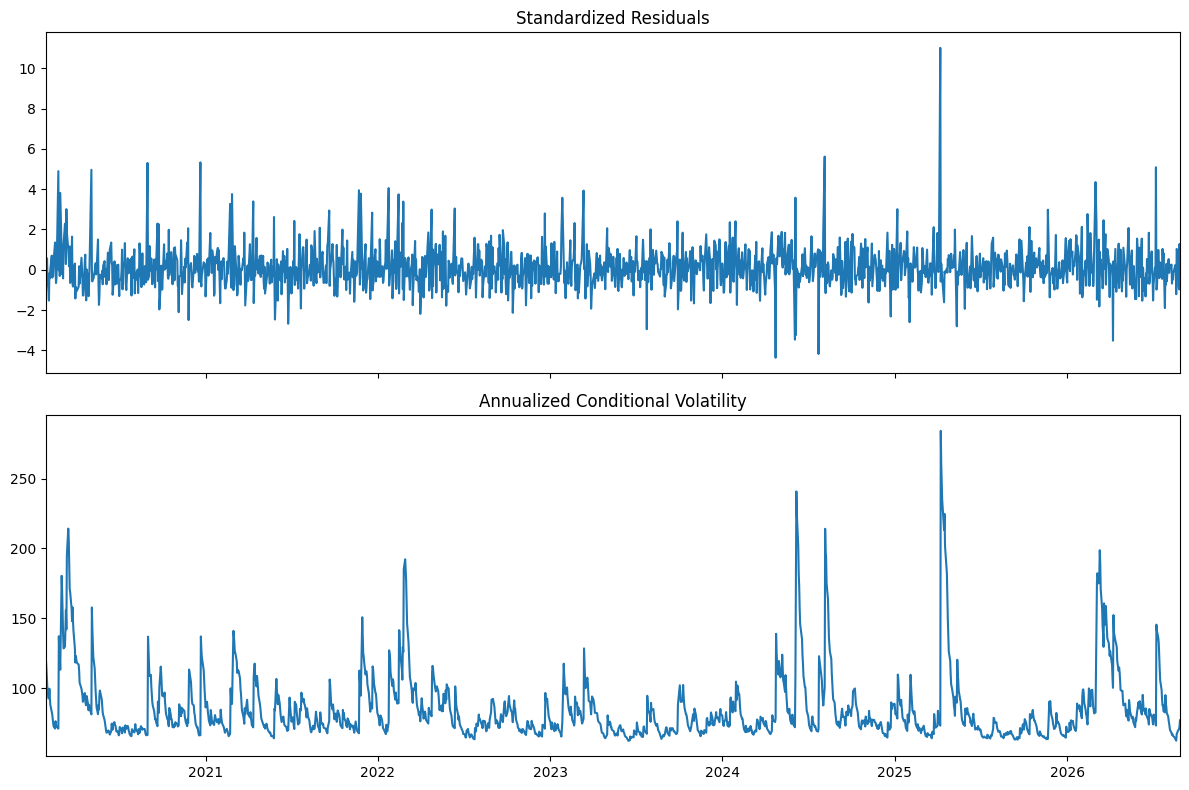

In [ ]:
import numpy as np
from arch import arch_model

# Calculate log returns
df['Returns'] = 100 * np.log(df['Price'] / df['Price'].shift(1))
df_garch = df.dropna(subset=['Returns'])

# Fit GARCH(1,1) model on returns using Student's t-distribution
# We use a Constant Mean and GARCH(1,1) volatility
model_returns_t = arch_model(df_garch['Returns'], vol='Garch', p=1, q=1, dist='t')
res_returns_t = model_returns_t.fit(disp='off')

print(res_returns_t.summary())

# Plot the results
fig = res_returns_t.plot(annualize='D')
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

#### Interpretation of GARCH on Returns
- **$\\alpha[1]$**: Shows how much volatility reacts to recent market shocks.
- **$\\beta[1]$**: Shows the persistence of volatility (how long shocks take to die out).
- **Annualized Conditional Volatility**: The bottom plot now shows the time-varying risk (standard deviation) of the VIX returns.

### GARCH Error Comparison
We will now calculate the error metrics for the GARCH model's mean forecast to see how it compares to the previous models.

In [ ]:
# Get the GARCH mean forecast (from the t-distribution model)
df['GARCH_Forecast_t'] = res_returns_t.conditional_volatility # This is the volatility, the mean forecast is usually res_returns.params['mu']
# For error comparison of the mean, we use the 'mu' or fitted values
y_pred_garch_t = res_returns_t.params['mu'] * np.ones(len(df['Price']))

mae_garch_t = mean_absolute_error(df['Price'], y_pred_garch_t)
mse_garch_t = mean_squared_error(df['Price'], y_pred_garch_t)
rmse_garch_t = np.sqrt(mse_garch_t)
mape_garch_t = mean_absolute_percentage_error(df['Price'], y_pred_garch_t)

# Add to comparison
all_model_metrics['GARCH(1,1) (t-dist)'] = {
    'MAE': mae_garch_t,
    'MSE': mse_garch_t,
    'RMSE': rmse_garch_t,
    'MAPE': mape_garch_t
}

# Update summary table
metrics_summary_df = pd.DataFrame(all_model_metrics).T
display(metrics_summary_df.round(4).style.apply(highlight_min, subset=pd.Index(metrics_summary_df.columns)))

,MAE,MSE,RMSE,MAPE
Naive Baseline,0.705200,1.535700,1.239200,3.750900
Single Exponential Smoothing (SES),0.704800,1.534800,1.238900,3.748600
Double Exponential Smoothing (DES),0.704500,1.534800,1.238900,3.746300
Triple Exponential Smoothing (TES - Additive),0.697800,1.361200,1.166700,3.818700
Triple Exponential Smoothing (TES - Multiplicative),0.679800,1.092300,1.045100,3.876500
"ARIMA(1,0,0)",0.702400,1.524700,1.234800,3.756800
"GARCH(1,1) (t-dist)",17.636800,367.222900,19.163100,102.307900


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Add Moving Average model metrics to the overall comparison
for model_name, metrics in error_metrics.items():
    all_model_metrics[model_name] = metrics

# Recreate and display the updated summary table
metrics_summary_df = pd.DataFrame(all_model_metrics).T

print("### Updated Summary of All Model Error Metrics (with Moving Averages) ###")
display(metrics_summary_df.round(4).style.apply(highlight_min, subset=pd.Index(metrics_summary_df.columns)))

### Updated Summary of All Model Error Metrics (with Moving Averages) ###


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,MAE,MSE,RMSE,MAPE
Naive Baseline,0.705200,1.535700,1.239200,3.750900
Single Exponential Smoothing (SES),0.704800,1.534800,1.238900,3.748600
Double Exponential Smoothing (DES),0.704500,1.534800,1.238900,3.746300
Triple Exponential Smoothing (TES - Additive),0.697800,1.361200,1.166700,3.818700
Triple Exponential Smoothing (TES - Multiplicative),0.679800,1.092300,1.045100,3.876500
"ARIMA(1,0,0)",0.702400,1.524700,1.234800,3.756800
"GARCH(1,1) (t-dist)",17.636800,367.222900,19.163100,102.307900
SMA_3M,2.286400,11.129900,3.336200,13.212400
SMA_5M,2.707500,14.664800,3.829500,16.458900
SMA_7M,2.837900,15.289300,3.910100,17.733000


## ARIMA(1,1,1) Model

Based on your request, we will now fit an ARIMA model with `p=1`, `d=1`, and `q=1` to the data.

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

# Define the ARIMA order as (1,1,1)
order_111 = (1, 1, 1)

# Fit the ARIMA(1,1,1) model
print(f"Fitting ARIMA{order_111} model...")
model_arima_111 = ARIMA(df['Price'], order=order_111)
fit_arima_111 = model_arima_111.fit()

Fitting ARIMA(1, 1, 1) model...


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC

In [ ]:
print(fit_arima_111.summary())

# Get in-sample predictions
df['ARIMA_111_Forecast'] = fit_arima_111.fittedvalues

# Drop NaN values for error calculation
actuals_arima_111 = df['Price'].dropna()
predictions_arima_111 = df['ARIMA_111_Forecast'].dropna()

# Align actuals and predictions based on their index
common_index_arima_111 = actuals_arima_111.index.intersection(predictions_arima_111.index)
y_true_arima_111 = actuals_arima_111.loc[common_index_arima_111]
y_pred_arima_111 = predictions_arima_111.loc[common_index_arima_111]


                               SARIMAX Results                                
Dep. Variable:                  Price   No. Observations:                 1634
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -2659.222
Date:                Sun, 30 Aug 2026   AIC                           5324.444
Time:                        07:01:39   BIC                           5340.638
Sample:                             0   HQIC                          5330.451
                               - 1634                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8261      0.029     28.668      0.000       0.770       0.883
ma.L1         -0.7696      0.035    -22.235      0.000      -0.837      -0.702
sigma2         1.5204      0.017     89.884      0.0

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Calculate error metrics
mae_arima_111 = mean_absolute_error(y_true_arima_111, y_pred_arima_111)
mse_arima_111 = mean_squared_error(y_true_arima_111, y_pred_arima_111)
rmse_arima_111 = np.sqrt(mse_arima_111)
mape_arima_111 = mean_absolute_percentage_error(y_true_arima_111, y_pred_arima_111)

# Display error metrics
print(f"\n--- ARIMA{order_111} Model Error Metrics ---")
print(f"MAE: {mae_arima_111:.4f}")
print(f"MSE: {mse_arima_111:.4f}")
print(f"RMSE: {rmse_arima_111:.4f}")
print(f"MAPE: {mape_arima_111:.4f}%")

# Add to comparison
all_model_metrics[f'ARIMA{order_111}'] = {
    'MAE': mae_arima_111,
    'MSE': mse_arima_111,
    'RMSE': rmse_arima_111,
    'MAPE': mape_arima_111
}



--- ARIMA(1, 1, 1) Model Error Metrics ---
MAE: 0.7185
MSE: 1.7026
RMSE: 1.3048
MAPE: 3.8378%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



### Updated Summary of All Model Error Metrics (with ARIMA(1,1,1)) ###


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,MAE,MSE,RMSE,MAPE,AIC,BIC
Naive Baseline,0.705200,1.535700,1.239200,3.750900,nan,nan
Single Exponential Smoothing (SES),0.704800,1.534800,1.238900,3.748600,704.004800,714.802400
Double Exponential Smoothing (DES),0.704500,1.534800,1.238900,3.746300,707.988400,729.583500
Triple Exponential Smoothing (TES - Additive),0.697800,1.361200,1.166700,3.818700,1015.827200,2397.916500
Triple Exponential Smoothing (TES - Multiplicative),0.679800,1.092300,1.045100,3.876500,656.260700,2038.350000
"ARIMA(1,0,0)",0.702400,1.524700,1.234800,3.756800,5335.849400,5352.045800
"GARCH(1,1) (t-dist)",17.636800,367.222900,19.163100,102.307900,9708.671600,9735.662500
SMA_3M,2.286400,11.129900,3.336200,13.212400,nan,nan
SMA_5M,2.707500,14.664800,3.829500,16.458900,nan,nan
SMA_7M,2.837900,15.289300,3.910100,17.733000,nan,nan


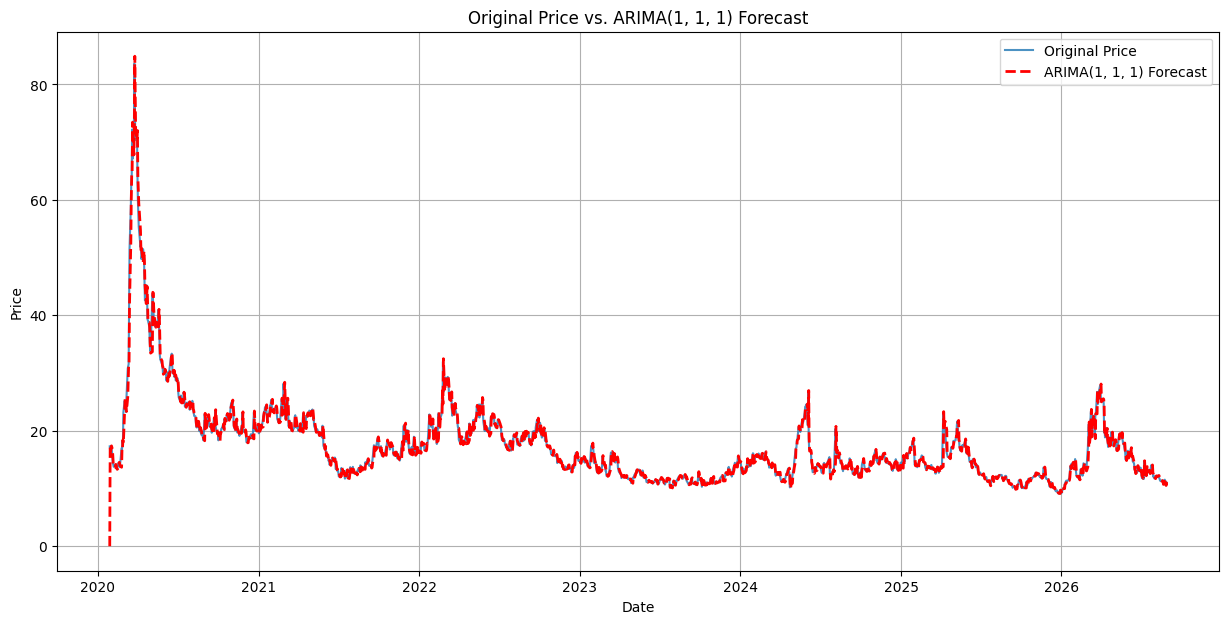

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Update summary table
metrics_summary_df = pd.DataFrame(all_model_metrics).T
print("\n### Updated Summary of All Model Error Metrics (with ARIMA(1,1,1)) ###")
display(metrics_summary_df.round(4).style.apply(highlight_min, subset=pd.Index(metrics_summary_df.columns)))

# Plot the results
plt.figure(figsize=(15, 7))
plt.plot(df['Price'], label='Original Price', alpha=0.8)
plt.plot(df['ARIMA_111_Forecast'], label=f'ARIMA{order_111} Forecast', color='red', linewidth=2, linestyle='--') # Changed color to red and linestyle to dashed
plt.title(f'Original Price vs. ARIMA{order_111} Forecast')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

## AIC and BIC Comparison

Let's compile the AIC (Akaike Information Criterion) and BIC (Bayesian Information Criterion) for all models where these metrics are applicable. Lower values for AIC and BIC generally indicate a better fit, penalizing model complexity.

In [ ]:
# Helper function to safely get AIC/BIC
def get_aic_bic(fit_obj):
    aic = getattr(fit_obj, 'aic', np.nan)
    bic = getattr(fit_obj, 'bic', np.nan)
    return aic, bic

# List of (model_name, fit_object_variable_name) to process
models_to_update = [
    ('Single Exponential Smoothing (SES)', 'fit_ses'),
    ('Double Exponential Smoothing (DES)', 'fit_des'),
    ('Triple Exponential Smoothing (TES - Additive)', 'fit_tes'),
    ('Triple Exponential Smoothing (TES - Multiplicative)', 'fit_tes_mul'),
    ('ARIMA(1,0,0)', 'fit_arima'),
    (f'ARIMA{best_order}', 'best_model'), # Assumes best_order and best_model exist
    ('GARCH(1,1) (t-dist)', 'res_returns_t'),
    (f'ARIMA{order_111}', 'fit_arima_111') # Assumes order_111 and fit_arima_111 exist
]

# Iterate through and update all_model_metrics
for model_name, fit_obj_name in models_to_update:
    if model_name in all_model_metrics and fit_obj_name in globals():
        fit_obj = globals()[fit_obj_name]
        aic, bic = get_aic_bic(fit_obj)
        all_model_metrics[model_name]['AIC'] = aic
        all_model_metrics[model_name]['BIC'] = bic

# The SARIMA model was deleted in the previous turns, so ensure it's not referenced
# If a SARIMA model was explicitly run and fit_sarima exists, you could add it here:
# if 'SARIMA(1,0,0)(1,0,0,252)' in all_model_metrics and 'fit_sarima' in globals(): # Example model name
#     aic, bic = get_aic_bic(globals()['fit_sarima'])
#     all_model_metrics['SARIMA(1,0,0)(1,0,0,252)']['AIC'] = aic
#     all_model_metrics['SARIMA(1,0,0)(1,0,0,252)']['BIC'] = bic

# Convert to DataFrame for display, handling missing AIC/BIC for some models
metrics_summary_df = pd.DataFrame(all_model_metrics).T

print("### Full Summary of All Model Error Metrics (with AIC/BIC) ###")
display(metrics_summary_df.round(4).style.apply(highlight_min, subset=pd.Index(metrics_summary_df.columns)))


### Full Summary of All Model Error Metrics (with AIC/BIC) ###


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,MAE,MSE,RMSE,MAPE,AIC,BIC
Naive Baseline,0.705200,1.535700,1.239200,3.750900,nan,nan
Single Exponential Smoothing (SES),0.704800,1.534800,1.238900,3.748600,704.004800,714.802400
Double Exponential Smoothing (DES),0.704500,1.534800,1.238900,3.746300,707.988400,729.583500
Triple Exponential Smoothing (TES - Additive),0.697800,1.361200,1.166700,3.818700,1015.827200,2397.916500
Triple Exponential Smoothing (TES - Multiplicative),0.679800,1.092300,1.045100,3.876500,656.260700,2038.350000
"ARIMA(1,0,0)",0.702400,1.524700,1.234800,3.756800,5335.849400,5352.045800
"GARCH(1,1) (t-dist)",17.636800,367.222900,19.163100,102.307900,9708.671600,9735.662500
SMA_3M,2.286400,11.129900,3.336200,13.212400,nan,nan
SMA_5M,2.707500,14.664800,3.829500,16.458900,nan,nan
SMA_7M,2.837900,15.289300,3.910100,17.733000,nan,nan


## Combined Model Forecasts Visualization

This chart visualizes the original India VIX Price alongside the in-sample forecasts from all the models we've implemented. This allows for a direct visual comparison of how well each model captures the dynamics of the time series.

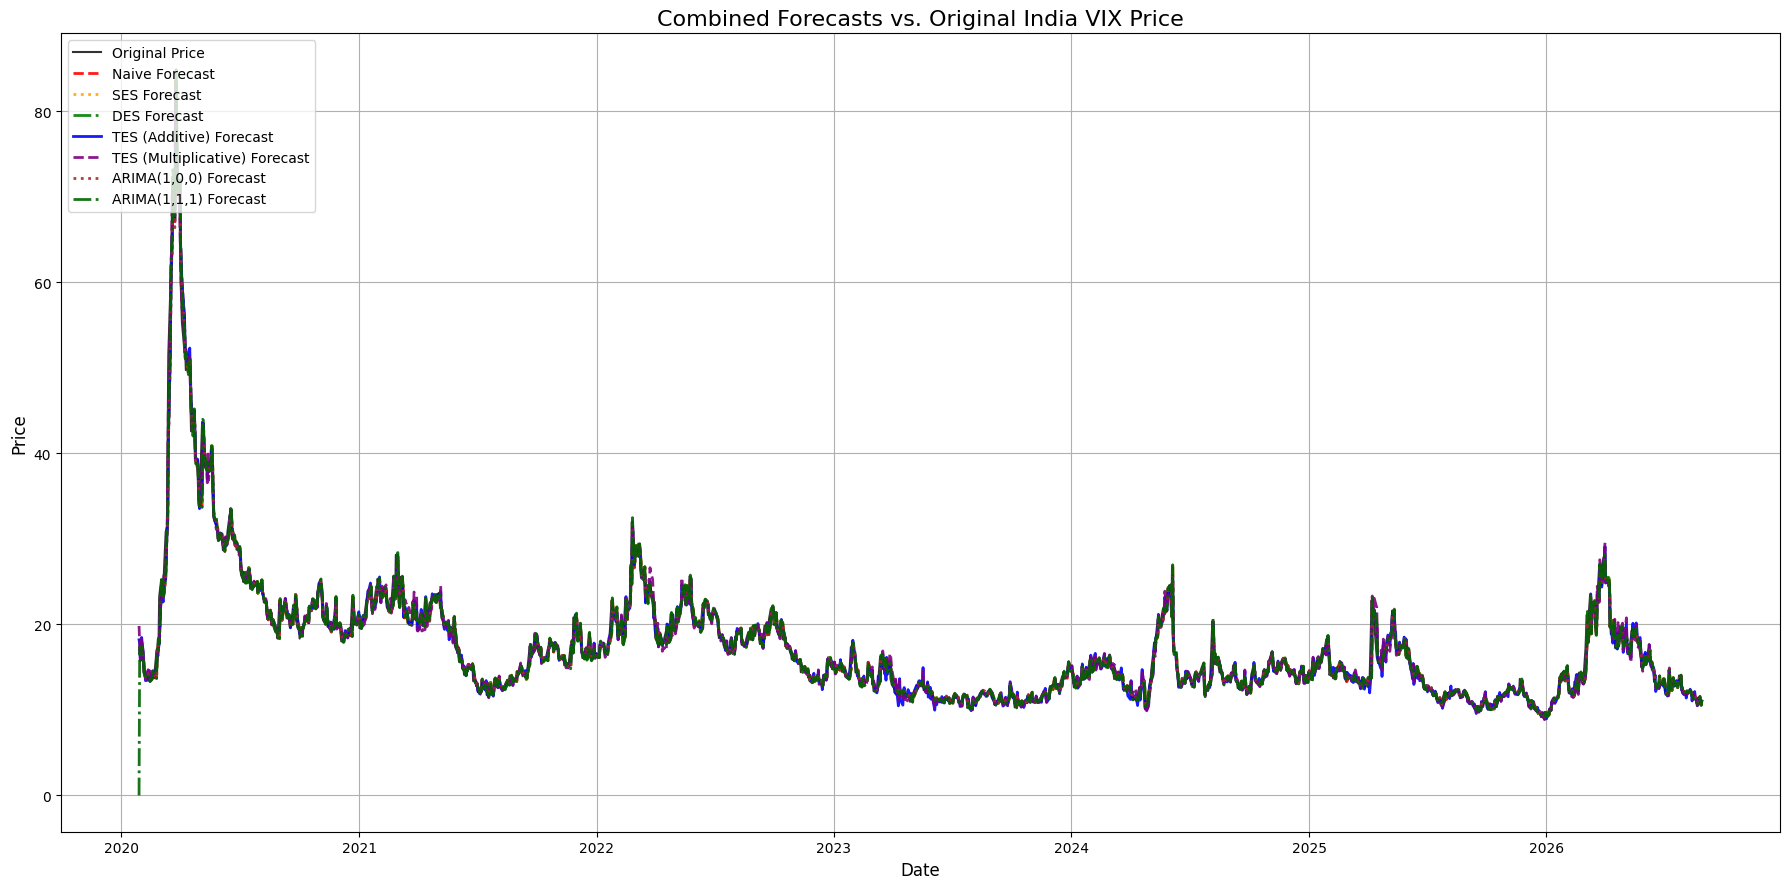

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
plt.figure(figsize=(18, 9))
plt.plot(df['Price'], label='Original Price', alpha=0.8, linewidth=1.5, color='black')

# Plot forecasts if available
if 'Naive_Forecast' in df.columns:
    plt.plot(df['Naive_Forecast'], label='Naive Forecast', alpha=0.9, linestyle='--', color='red', linewidth=2)
if 'SES_Forecast' in df.columns:
    plt.plot(df['SES_Forecast'], label='SES Forecast', alpha=0.9, linestyle=':', color='orange', linewidth=2)
if 'DES_Forecast' in df.columns:
    plt.plot(df['DES_Forecast'], label='DES Forecast', alpha=0.9, linestyle='-.', color='green', linewidth=2)
if 'TES_Forecast' in df.columns:
    plt.plot(df['TES_Forecast'], label='TES (Additive) Forecast', alpha=0.9, linestyle='solid', color='blue', linewidth=2)
if 'TES_Mul_Forecast' in df.columns:
    plt.plot(df['TES_Mul_Forecast'], label='TES (Multiplicative) Forecast', alpha=0.9, linestyle='dashed', color='purple', linewidth=2)
if 'ARIMA_Forecast' in df.columns:
    plt.plot(df['ARIMA_Forecast'], label='ARIMA(1,0,0) Forecast', alpha=0.9, linestyle='dotted', color='brown', linewidth=2)
if 'ARIMA_111_Forecast' in df.columns:
    plt.plot(df['ARIMA_111_Forecast'], label='ARIMA(1,1,1) Forecast', alpha=0.9, linestyle='-.', color='darkgreen', linewidth=2)
# Note: GARCH_Forecast_t is conditional volatility, not directly comparable on this scale for price forecast

plt.title('Combined Forecasts vs. Original India VIX Price', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.legend(loc='upper left', fontsize=10)
plt.grid(True)
plt.tight_layout()
plt.show()

## Forecasting Future Values with the Best Model

Based on our model comparison, the **Triple Exponential Smoothing (TES - Multiplicative)** model yielded the lowest RMSE and MSE for price level forecasting. We will now use this model (`fit_tes_mul`) to generate future forecasts for the India VIX price.

In [ ]:
import pandas as pd

# Define the number of future steps to forecast
n_forecast_steps = 100

# Generate future forecasts using the fitted TES Multiplicative model
future_forecasts = fit_tes_mul.forecast(steps=n_forecast_steps)

# Create a date range for the future forecasts
last_date = df.index.max()
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_forecast_steps, freq='B') # 'B' for business day frequency

# Assign the new DatetimeIndex to the future_forecasts Series
future_forecasts.index = future_dates

# Create a DataFrame for future forecasts using the Series with the correct index
future_df = pd.DataFrame({'TES_Mul_Forecast': future_forecasts})

# Combine historical data and future forecasts for plotting
combined_df = pd.concat([df[['Price', 'TES_Mul_Forecast']], future_df])

display(combined_df.tail(n_forecast_steps + 5))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Price,TES_Mul_Forecast
2026-08-24,11.5250,11.374508
2026-08-25,11.0750,11.365024
2026-08-26,10.5650,11.057270
2026-08-27,11.1625,10.636574
2026-08-28,10.8850,11.141652
...,...,...
2027-01-11,NaN,10.253650
2027-01-12,NaN,10.590508
2027-01-13,NaN,10.374803
2027-01-14,NaN,10.129791


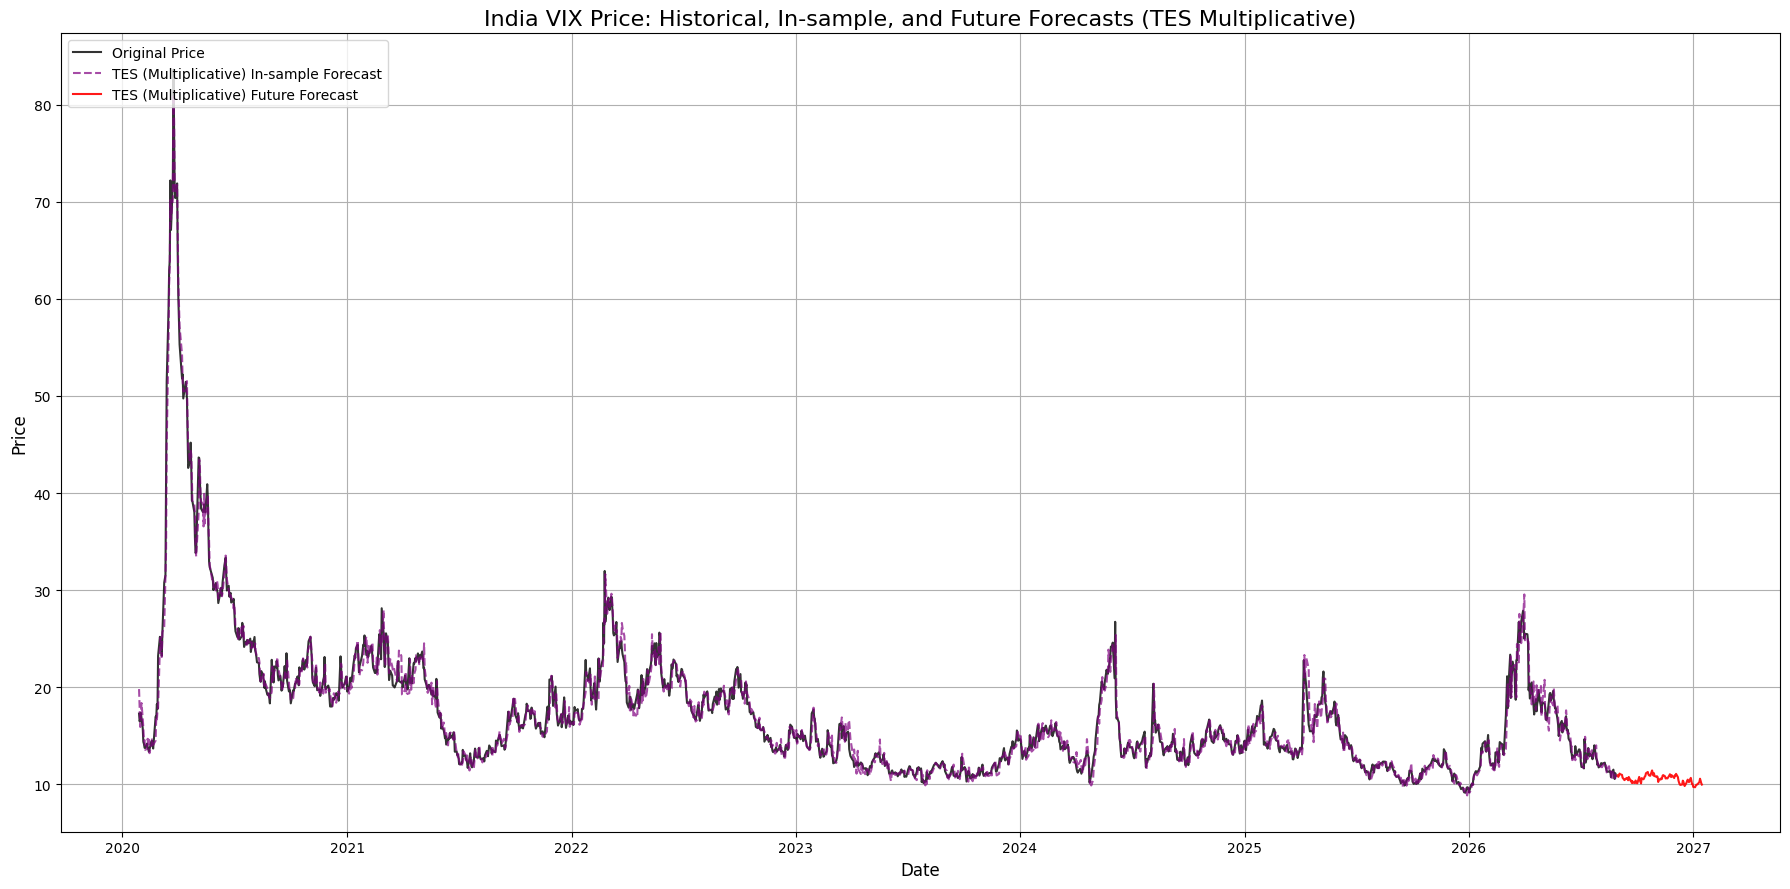

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Plot the historical data, in-sample forecast, and future forecast
plt.figure(figsize=(18, 9))
plt.plot(df['Price'], label='Original Price', alpha=0.8, linewidth=1.5, color='black')
plt.plot(df['TES_Mul_Forecast'], label='TES (Multiplicative) In-sample Forecast', alpha=0.7, linestyle='--', color='purple')
plt.plot(future_df.index, future_df['TES_Mul_Forecast'], label='TES (Multiplicative) Future Forecast', alpha=0.9, linestyle='-', color='red')

plt.title('India VIX Price: Historical, In-sample, and Future Forecasts (TES Multiplicative)', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.legend(loc='upper left', fontsize=10)
plt.grid(True)
plt.tight_layout()
plt.show()